# Analisis Sentimen Publik terhadap AI yang Menggantikan Pekerjaan Manusia

**Mata Kuliah:** Data Mining
**Nama:** Muhammad Rafa Enrico (TI-3C)
**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

## Rumusan Masalah
1. Bagaimana sebaran sentimen publik (positif, negatif, netral) terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube?
2. Algoritma klasifikasi mana (Naive Bayes, SVM, Random Forest) yang memberikan performa terbaik dalam mengklasifikasikan sentimen tersebut?

## Tujuan
1. Mengetahui sebaran sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia.
2. Membandingkan performa algoritma klasifikasi untuk menentukan algoritma terbaik.

## Alur Penelitian

### A. Persiapan Data (Google Colab)
1. **Instalasi Library** — menyiapkan library untuk scraping, deteksi bahasa, dan pelabelan.
2. **Pengumpulan Data (Scraping)** — mengambil 4.423 komentar dari 6 video YouTube bertema AI dan pekerjaan.
3. **Pemahaman Data Awal** — mengenal gambaran umum data mentah: ukuran, tipe data, contoh isi, sebaran per video, panjang komentar, likes, dan format waktu.
4. **Data Cleaning** — membersihkan data dengan pola cek → bersihkan → verifikasi pada setiap langkah: nilai kosong, duplikat, spam judi online, karakter tak terlihat, URL, mention, spasi berlebih, komentar terlalu pendek, komentar tanpa huruf, format likes, format waktu, dan deteksi bahasa.
5. **Pelabelan Sentimen** — memberi label positif, negatif, atau netral secara otomatis menggunakan model multilingual XLM-RoBERTa.
6. **Validasi Label** — membandingkan label model dengan penilaian manual pada 30 sampel (10 per kelas).
7. **Exploratory Data Analysis (EDA)** — menganalisis distribusi sentimen, perbandingan per video dan per bahasa, panjang komentar, serta kata yang paling sering muncul.

### B. Pemodelan dan Evaluasi (Orange Data Mining)
8. **Text Preprocessing** — case folding, tokenisasi, penghapusan stopword bahasa Indonesia dan Inggris, serta filtering kata.
9. **Ekstraksi Fitur** — mengubah teks menjadi angka dengan TF-IDF.
10. **Pemodelan** — membandingkan 5 algoritma: Naive Bayes, Logistic Regression, SVM, Random Forest, dan kNN.
11. **Evaluasi** — 10-fold cross-validation dengan metrik akurasi, precision, recall, F1-score, dan confusion matrix.
12. **Interpretasi Hasil** — menentukan model terbaik dan menganalisis kata-kata yang paling berpengaruh pada tiap sentimen.

## Tahap 1: Instalasi Library
Library yang dibutuhkan: `youtube-comment-downloader` untuk scraping, `langdetect` untuk deteksi bahasa, serta `transformers` dan `torch` untuk labeling sentimen.

In [1]:
!pip install youtube-comment-downloader langdetect transformers torch --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 18.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 16.0 MB/s eta 0:00:00


## Tahap 2: Scraping Data
Mengambil komentar dari 6 video YouTube bertema AI dan pekerjaan (2 video berbahasa Indonesia, 4 video berbahasa Inggris). Komentar diurutkan dari yang terpopuler. Jumlah per video dibatasi maksimal 1.500 agar satu video tidak mendominasi dataset.

Data diambil pada 12 Oktober 2026. Hasil: 4.458 komentar, disimpan di
`youtube_comments.csv`.

In [ ]:
!python scrape_youtube_comments.py

python3: can't open file '/content/scrape_youtube_comments.py': [Errno 2] No such file or directory


## Tahap 3: Pemahaman Data Awal (Data Understanding)

Tahap ini bertujuan mengenal **gambaran umum** data mentah hasil scraping: seberapa besar datanya, apa saja kolomnya, seperti apa isinya, dan bagaimana sebarannya. Data tidak diubah sama sekali pada tahap ini.

Pengecekan masalah kualitas data (nilai kosong, duplikat, URL, spam, dan lainnya) dilakukan langsung di Tahap 4, dengan pola **cek → bersihkan → verifikasi** pada setiap langkah.

Pemeriksaan yang dilakukan:
1. Ukuran dan struktur dataset
2. Tipe data tiap kolom
3. Contoh isi data
4. Jumlah komentar per video
5. Distribusi panjang komentar
6. Distribusi jumlah likes
7. Format kolom waktu
8. Kesimpulan pemahaman data

### 3.1 Ukuran dan Struktur Dataset
Memuat file hasil scraping dan melihat jumlah baris serta kolomnya. Data mentah disimpan di variabel `df_raw` dan tidak diubah selama tahap ini.

Fungsi `tampilkan_tabel()` dipakai di seluruh notebook untuk menampilkan hasil dalam bentuk tabel yang rapi, tanpa nomor indeks, dengan format angka Indonesia (titik untuk ribuan, koma untuk desimal).

| Kolom | Keterangan |
|---|---|
| `video_url` | Tautan video asal komentar |
| `author` | Nama akun pemberi komentar |
| `comment` | Isi komentar |
| `likes` | Jumlah like pada komentar |
| `time` | Waktu komentar dibuat (format relatif dari YouTube) |

In [3]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)

def tampilkan_tabel(data):
    # Tabel tanpa nomor indeks, angka berformat Indonesia (1.500 dan 33,6).
    # Kolom desimal yang isinya bilangan bulat semua ditampilkan tanpa ",0".
    data = data.copy()
    for kolom in data.columns:
        if pd.api.types.is_float_dtype(data[kolom]) and (data[kolom].dropna() % 1 == 0).all():
            data[kolom] = data[kolom].astype("Int64")
    display(data.style.hide(axis="index").format(precision=1, thousands=".", decimal=","))

df_raw = pd.read_csv("youtube_comments.csv")

tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Jumlah baris (komentar)", "Jumlah kolom"],
    "Nilai": [df_raw.shape[0], df_raw.shape[1]],
}))

Keterangan,Nilai
Jumlah baris (komentar),4.458
Jumlah kolom,5


In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4458 entries, 0 to 4457
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   video_url  4458 non-null   object
 1   author     4458 non-null   object
 2   comment    4458 non-null   object
 3   likes      4458 non-null   object
 4   time       4458 non-null   object
dtypes: object(5)
memory usage: 174.3+ KB


In [6]:
df_raw.head()

,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,2 maanden geleden


### 3.2 Tipe Data Tiap Kolom
Memeriksa apakah tipe data sudah sesuai. Tipe `object` berarti kolom terbaca sebagai teks. Kolom `likes` seharusnya berupa angka. Kalau terbaca sebagai teks, berarti ada nilai yang formatnya tidak murni angka.

In [7]:
info_kolom = pd.DataFrame({
    "Kolom": df_raw.columns,
    "Tipe data": df_raw.dtypes.astype(str).values,
    "Jumlah terisi": df_raw.notnull().sum().values,
    "Jumlah kosong": df_raw.isnull().sum().values,
    "Contoh nilai": [str(df_raw[k].iloc[0])[:60] for k in df_raw.columns],
})
tampilkan_tabel(info_kolom)

likes_teks = df_raw["likes"].astype(str).str.strip()
bukan_angka = likes_teks[~likes_teks.str.fullmatch(r"\d+")]

print(f"\nNilai likes yang bukan angka murni: {len(bukan_angka)}")
tampilkan_tabel(bukan_angka.value_counts().head(10).rename_axis("Nilai likes").reset_index(name="Jumlah"))

Kolom,Tipe data,Jumlah terisi,Jumlah kosong,Contoh nilai
video_url,object,4.458,0,https://www.youtube.com/watch?v=t2WmNcToB3I
author,object,4.458,0,@aprie_rdw
comment,object,4.458,0,Bahas imigrant maroko yg nyebrang ke spanyol donk bang
likes,object,4.458,0,413
time,object,4.458,0,2 maanden geleden



Nilai likes yang bukan angka murni: 43


Nilai likes,Jumlah
"1,5K",3
"1,7K",2
"3,8K",2
14K,2
"6,1K",2
"1,4K",2
"6,5K",1
11K,1
30K,1
13K,1


**Catatan:** YouTube menyingkat jumlah like yang besar, misalnya `11K` (11.000) atau `6,5K` (6.500). Tanda desimalnya bisa koma atau titik, tergantung bahasa tampilan YouTube saat scraping. Karena itu kolom `likes` terbaca sebagai teks, dan nilainya diubah menjadi angka di Tahap 4.

### 3.3 Contoh Isi Data
Menampilkan 10 baris pertama dan 5 baris acak untuk melihat gambaran isi komentar secara langsung.

In [8]:
print("10 baris pertama:")
display(df_raw.head(10))

print("5 baris acak:")
display(df_raw.sample(5, random_state=42))

10 baris pertama:


,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,2 maanden geleden
5,https://www.youtube.com/watch?v=t2WmNcToB3I,@bayurocky1326,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih b...",21,2 maanden geleden
6,https://www.youtube.com/watch?v=t2WmNcToB3I,@elelelelel0101,gw berani taruhan kalo dampak buruk AI lebih banyak ketimbang manfaatnya,6,2 maanden geleden
7,https://www.youtube.com/watch?v=t2WmNcToB3I,@fachrudinfachru3050,"Bukan hanya AI yang mengubah dunia kerja, aplikasi online juga telah mengubah hampir semua bidang usaha. Jual beli k...",31,2 maanden geleden
8,https://www.youtube.com/watch?v=t2WmNcToB3I,@jeraora3045,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya,115,2 maanden geleden
9,https://www.youtube.com/watch?v=t2WmNcToB3I,@luvhkm,"BANG BAHAS DEMO YG GAK DI TAYANGIN DI TV, MALAH BUZZER PADA NGIRIM MEME DOKSLI",192,2 maanden geleden


5 baris acak:


,video_url,author,comment,likes,time
387,https://www.youtube.com/watch?v=t2WmNcToB3I,@PengenMainDota2,Ai harus ditolak di berbagai sektor pekerjaan,1,2 maanden geleden
3482,https://www.youtube.com/watch?v=s1c4Ji6tNdw,@zipster999,I think the OP was rather suggesting that what you describe is the profile of a lot of CEOs already!,3,7 maanden geleden
1330,https://www.youtube.com/watch?v=F8pz5wIO6gA,@kursusmenjahitlpk.mentari4924,😊😊,1,10 dagen geleden
2905,https://www.youtube.com/watch?v=7Pq-S557XQU,@KManAbout,That is the point Tysej4,0,8 jaar geleden
1833,https://www.youtube.com/watch?v=7Pq-S557XQU,@violenceisfun991,@CromemcoZ2 i don't have a basement i live in a flat so to me a basement is someone's home,8,5 jaar geleden


### 3.4 Jumlah Komentar per Video
Melihat sebaran komentar dari keenam video. Video *Humans Need Not Apply* dibatasi 1.500 komentar saat scraping agar tidak mendominasi dataset.

Video,Jumlah komentar,Persentase (%)
Humans Need Not Apply (EN),1.500,"33,6"
UK unemployment soars (EN),912,"20,5"
Manusia Belum Tergantikan AI (ID),867,"19,4"
Pekerja Latih Robot (ID),819,"18,4"
The EXACT moment AI took my job (EN),230,"5,2"
AI is taking their jobs (EN),130,"2,9"


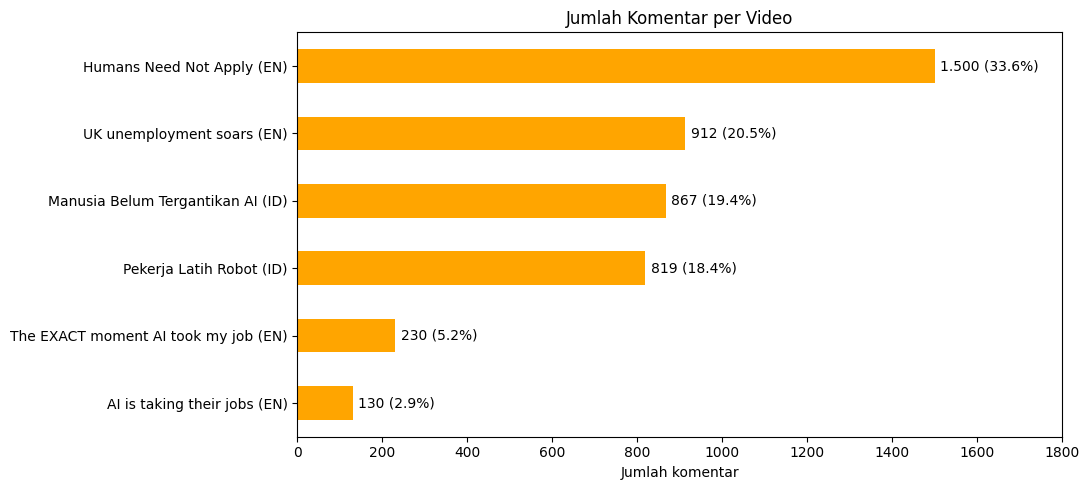

In [9]:
judul_video = {
    "t2WmNcToB3I": "Pekerja Latih Robot (ID)",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI (ID)",
    "7Pq-S557XQU": "Humans Need Not Apply (EN)",
    "SDich6serU0": "The EXACT moment AI took my job (EN)",
    "s1c4Ji6tNdw": "UK unemployment soars (EN)",
    "0LOHWGQwKtM": "AI is taking their jobs (EN)",
}

video_id = df_raw["video_url"].str[-11:]
per_video = video_id.map(judul_video).value_counts().rename_axis("video").reset_index(name="jumlah_komentar")
per_video["persentase"] = (per_video["jumlah_komentar"] / len(df_raw) * 100).round(1)

tampilkan_tabel(per_video.rename(columns={
    "video": "Video", "jumlah_komentar": "Jumlah komentar", "persentase": "Persentase (%)"}))

ax = per_video.plot(kind="barh", x="video", y="jumlah_komentar", legend=False, color="orange",
                    title="Jumlah Komentar per Video", figsize=(11, 5))
ax.invert_yaxis()
ax.set_xlabel("Jumlah komentar")
ax.set_ylabel("")

# Angka di ujung setiap bar: jumlah komentar dan persentasenya
label = [f"{n:,} ({p}%)".replace(",", ".") for n, p in zip(per_video["jumlah_komentar"], per_video["persentase"])]
ax.bar_label(ax.containers[0], labels=label, padding=4)
ax.set_xlim(0, per_video["jumlah_komentar"].max() * 1.2)  # ruang di kanan agar label tidak terpotong

plt.tight_layout()
plt.show()

### 3.5 Distribusi Panjang Komentar
Melihat seberapa panjang komentar pada umumnya, dalam jumlah karakter dan jumlah kata. Informasi ini membantu menentukan batas komentar yang terlalu pendek di Tahap 4.

Statistik,Jumlah karakter,Jumlah kata
Jumlah komentar,"4.458,0","4.458,0"
Rata-rata,"165,0","27,8"
Standar deviasi,"222,1","37,1"
Minimum,"1,0","1,0"
Kuartil 1 (25%),"43,0","7,0"
Median (50%),"89,0","15,0"
Kuartil 3 (75%),"199,0","33,0"
Maksimum,"3.179,0","501,0"


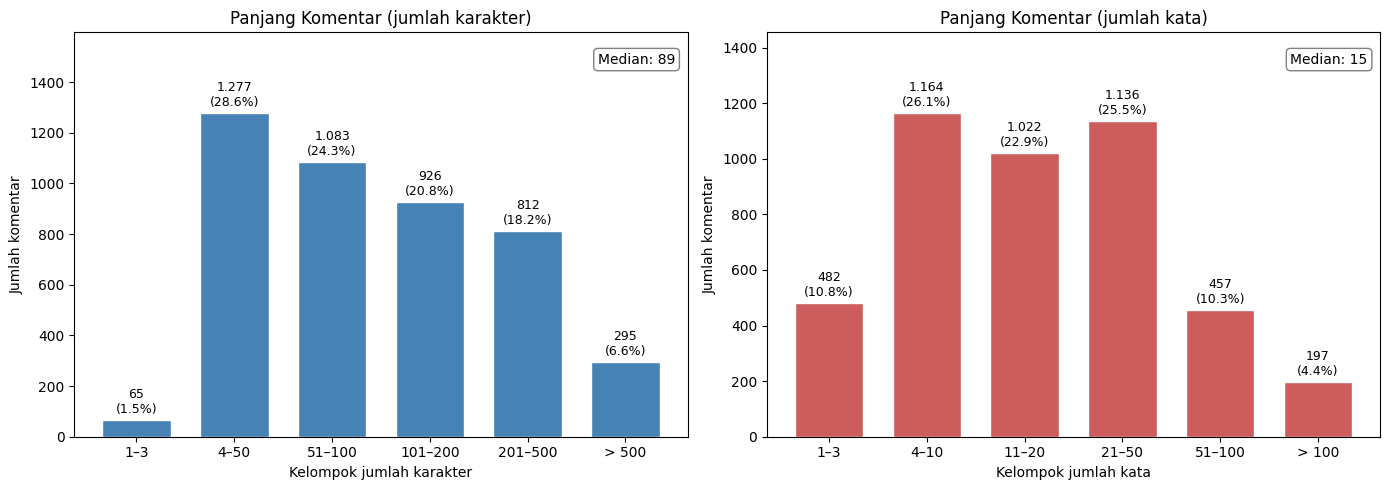

Keterangan,Jumlah karakter,Isi komentar (150 karakter pertama)
Komentar terpendek,1,🫨
Komentar terpanjang,3.179,"saya kerjanya di bidang grafis dan vfx... sy melihat dulu production house selalu hire 3D artist utk CGI... sekarang dalam setahun paling cuma 1 kali, ..."


In [10]:
teks = df_raw["comment"].astype(str)
panjang_karakter = teks.str.len()
jumlah_kata = teks.str.split().str.len()

# Statistik deskriptif dengan nama baris berbahasa Indonesia
statistik = pd.DataFrame({
    "Jumlah karakter": panjang_karakter.describe(),
    "Jumlah kata": jumlah_kata.describe(),
}).round(1)
statistik.index = ["Jumlah komentar", "Rata-rata", "Standar deviasi", "Minimum",
                   "Kuartil 1 (25%)", "Median (50%)", "Kuartil 3 (75%)", "Maksimum"]
tampilkan_tabel(statistik.rename_axis("Statistik").reset_index())

# Mengelompokkan panjang komentar ke dalam rentang yang mudah dibaca
kelompok_karakter = pd.cut(panjang_karakter, bins=[0, 3, 50, 100, 200, 500, float("inf")],
                           labels=["1–3", "4–50", "51–100", "101–200", "201–500", "> 500"])
kelompok_kata = pd.cut(jumlah_kata, bins=[0, 3, 10, 20, 50, 100, float("inf")],
                       labels=["1–3", "4–10", "11–20", "21–50", "51–100", "> 100"])

def gambar_kelompok(ax, kelompok, judul, label_x, warna, median):
    jumlah = kelompok.value_counts().sort_index()
    persen = jumlah / jumlah.sum() * 100
    bar = ax.bar(jumlah.index.astype(str), jumlah.values, color=warna, edgecolor="white", width=0.7)
    label = [f"{n:,}".replace(",", ".") + f"\n({p:.1f}%)" for n, p in zip(jumlah, persen)]
    ax.bar_label(bar, labels=label, padding=3, fontsize=9)
    ax.set_ylim(0, jumlah.max() * 1.25)  # ruang di atas agar label tidak terpotong
    ax.set_title(judul)
    ax.set_xlabel(label_x)
    ax.set_ylabel("Jumlah komentar")
    ax.text(0.98, 0.95, f"Median: {median:.0f}", transform=ax.transAxes, ha="right", va="top",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gambar_kelompok(axes[0], kelompok_karakter, "Panjang Komentar (jumlah karakter)",
                "Kelompok jumlah karakter", "steelblue", panjang_karakter.median())
gambar_kelompok(axes[1], kelompok_kata, "Panjang Komentar (jumlah kata)",
                "Kelompok jumlah kata", "indianred", jumlah_kata.median())
plt.tight_layout()
plt.show()

tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Komentar terpendek", "Komentar terpanjang"],
    "Jumlah karakter": [panjang_karakter.min(), panjang_karakter.max()],
    "Isi komentar (150 karakter pertama)": [
        df_raw.loc[panjang_karakter.idxmin(), "comment"][:150].replace("\n", " "),
        df_raw.loc[panjang_karakter.idxmax(), "comment"][:150].replace("\n", " ") + " ...",
    ],
}))

### 3.6 Distribusi Jumlah Likes
Nilai likes dengan singkatan (`K` = ribu, `M` = juta) diubah sementara menjadi angka **hanya untuk melihat sebarannya**. Data asli di `df_raw` tetap tidak diubah.

In [11]:
def ubah_likes(nilai):
    # Koma dan titik sama-sama dianggap tanda desimal, karena format YouTube
    # bisa "6.1k" atau "6,5K" tergantung bahasa yang dipakai saat scraping
    n = str(nilai).strip().lower().replace(" ", "").replace(",", ".")
    for akhiran, kali in (("mln.", 1_000_000), ("mln", 1_000_000), ("jt", 1_000_000),
                          ("rb", 1_000), ("k", 1_000), ("m", 1_000_000)):
        if n.endswith(akhiran):
            return round(float(n[:-len(akhiran)]) * kali)
    return int(float(n)) if n else 0

likes_angka = df_raw["likes"].apply(ubah_likes)

statistik_likes = pd.DataFrame({
    "Statistik": ["Jumlah komentar", "Rata-rata", "Standar deviasi", "Minimum", "Kuartil 1 (25%)",
                  "Median (50%)", "Kuartil 3 (75%)", "Maksimum", "Komentar tanpa like (0)"],
    "Nilai": list(likes_angka.describe().round(1).values) + [(likes_angka == 0).sum()],
})
tampilkan_tabel(statistik_likes)
print(f"Persentase komentar tanpa like: {(likes_angka == 0).mean():.1%}".replace(".", ","))

print("\n5 komentar dengan like terbanyak:")
top = df_raw.assign(likes_angka=likes_angka).nlargest(5, "likes_angka")
tampilkan_tabel(pd.DataFrame({
    "Likes": top["likes_angka"].astype(int).values,
    "Komentar": top["comment"].str[:100].str.replace("\n", " ").values,
}))

Statistik,Nilai
Jumlah komentar,"4.458,0"
Rata-rata,"83,2"
Standar deviasi,"1.044,7"
Minimum,"0,0"
Kuartil 1 (25%),"0,0"
Median (50%),"0,0"
Kuartil 3 (75%),"3,0"
Maksimum,"31.000,0"
Komentar tanpa like (0),"2.400,0"


Persentase komentar tanpa like: 53,8%

5 komentar dengan like terbanyak:


Likes,Komentar
31.000,"""you might think technology can't replace your job"" I'd be pretty horrified if technology started re"
30.000,Aged like fine wine
26.000,I'd really like an updated version of this video.
24.000,"""The human brain is the most complicated machine, perhaps in the whole universe."" - Human Brain"
19.000,"So you think a bot can take my job? The joke's on you, I don't have a job!"


### 3.7 Format Kolom Waktu
Kolom `time` berisi waktu relatif dari YouTube yang dihitung dari tanggal scraping, bukan tanggal pasti. Bahasanya mengikuti tampilan YouTube saat scraping. Pada data ini muncul dalam bahasa Belanda, misalnya "2 maanden geleden" (2 bulan lalu) dan keterangan "(bewerkt)" (diedit) untuk komentar yang pernah diubah. Kolom **Arti** pada tabel di bawah adalah terjemahannya ke bahasa Indonesia.

In [12]:
kamus_waktu = {
    r"\bgeleden\b": "yang lalu", r"\bago\b": "yang lalu",
    r"\buur\b": "jam", r"\bhours?\b": "jam",
    r"\bdagen\b": "hari", r"\bdag\b": "hari", r"\bdays?\b": "hari",
    r"\bweken\b": "minggu", r"\bweek\b": "minggu", r"\bweeks\b": "minggu",
    r"\bmaanden\b": "bulan", r"\bmaand\b": "bulan", r"\bmonths?\b": "bulan",
    r"\bjaar\b": "tahun", r"\byears?\b": "tahun",
    r"\(bewerkt\)": "(diedit)", r"\(edited\)": "(diedit)",
}

frekuensi_waktu = df_raw["time"].value_counts().head(10).rename_axis("Nilai waktu").reset_index(name="Jumlah")
frekuensi_waktu.insert(1, "Arti", frekuensi_waktu["Nilai waktu"].replace(kamus_waktu, regex=True))
print("10 nilai waktu yang paling sering muncul:")
tampilkan_tabel(frekuensi_waktu)

diedit = df_raw["time"].astype(str).str.contains(r"edited|bewerkt|diedit", case=False, regex=True)
tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Jumlah nilai waktu yang berbeda", "Komentar yang pernah diedit"],
    "Nilai": [df_raw["time"].nunique(), diedit.sum()],
}))
print(f"Persentase komentar yang diedit: {diedit.mean():.1%}".replace(".", ","))

10 nilai waktu yang paling sering muncul:


Nilai waktu,Arti,Jumlah
2 maanden geleden,2 bulan yang lalu,933
7 maanden geleden,7 bulan yang lalu,795
5 jaar geleden,5 tahun yang lalu,373
6 jaar geleden,6 tahun yang lalu,366
3 weken geleden,3 minggu yang lalu,299
4 jaar geleden,4 tahun yang lalu,234
4 weken geleden,4 minggu yang lalu,227
1 maand geleden,1 bulan yang lalu,185
5 maanden geleden,5 bulan yang lalu,122
3 jaar geleden,3 tahun yang lalu,122


Keterangan,Nilai
Jumlah nilai waktu yang berbeda,62
Komentar yang pernah diedit,303


Persentase komentar yang diedit: 6,8%


**Catatan:** format waktu relatif ini belum bisa dihitung atau diurutkan. Di Tahap 4 (langkah 4.12), kolom ini diubah menjadi umur komentar dalam hari dan perkiraan tanggal agar bisa dipakai di tahap EDA. Kolom waktu tidak dipakai sebagai fitur dalam pemodelan.

### 3.8 Kesimpulan Pemahaman Data
- Dataset berisi komentar dari 6 video dengan 5 kolom, dan semua kolom terbaca sebagai teks.
- Kolom yang dipakai untuk analisis sentimen adalah `comment`. Kolom `video_url`, `likes`, dan `time` dipakai sebagai informasi pendukung.
- Kolom `likes` perlu diubah menjadi angka karena memakai singkatan seperti `11K` dan `6,5K`.
- Kolom `time` berupa waktu relatif berbahasa Belanda, sehingga perlu diubah menjadi angka (umur dalam hari) dan perkiraan tanggal.
- Panjang komentar sangat beragam, dari 1 karakter sampai ribuan karakter. Komentar yang terlalu pendek kemungkinan tidak membawa informasi sentimen.
- Kolom `author` tidak dipakai dalam analisis.

Masalah kualitas data diperiksa dan dibersihkan satu per satu di Tahap 4.

## Tahap 4: Data Cleaning/Preprocessing

Setiap langkah cleaning dikerjakan dengan pola yang sama:
1. **Cek**: menghitung berapa data yang bermasalah dan menampilkan contohnya.
2. **Bersihkan**: menghapus baris atau memperbaiki teksnya.
3. **Verifikasi**: memastikan masalahnya sudah tidak ada lagi.

Urutan langkah:

| No | Langkah | Tindakan |
|---|---|---|
| 4.1 | Nilai kosong | Hapus baris |
| 4.2 | Duplikat baris persis | Hapus, sisakan satu |
| 4.3 | Spam judi online | Hapus baris |
| 4.4 | Karakter tak terlihat (zero-width space) | Hapus karakternya |
| 4.5 | URL di dalam komentar | Hapus tautannya |
| 4.6 | Mention (@username) | Hapus teks mention |
| 4.7 | Baris baru dan spasi berlebih | Ganti dengan satu spasi |
| 4.8 | Duplikat teks komentar | Hapus, sisakan satu |
| 4.9 | Komentar kosong atau terlalu pendek | Hapus baris |
| 4.10 | Komentar tanpa huruf atau angka | Hapus baris |
| 4.11 | Format kolom likes | Ubah ke angka |
| 4.12 | Format kolom waktu | Ubah ke umur (hari), perkiraan tanggal, dan status diedit |
| 4.13 | Deteksi bahasa | Tambah kolom bahasa, hapus yang tidak terdeteksi |
| 4.14 | Ringkasan dan verifikasi akhir | — |
| 4.15 | Menyimpan hasil | — |

Langkah 4.4 sampai 4.7 hanya merapikan teks di kolom baru `comment_clean`, sedangkan kolom `comment` asli tetap disimpan apa adanya. Duplikat teks dan komentar pendek baru diperiksa **setelah** teks dirapikan, karena komentar seperti `@budi up` dan `@andi up` baru terlihat sama (`up`) setelah mention dihapus.

### 4.0 Persiapan
Membuat salinan data mentah ke variabel `df` agar `df_raw` tetap utuh sebagai pembanding. Fungsi bantu yang disiapkan:
- `catat()`: merekam hasil setiap langkah, yang nanti ditampilkan sebagai tabel ringkasan di langkah 4.14.
- `tampilkan_tabel()`: menampilkan tabel tanpa nomor indeks dengan format angka Indonesia.
- `hasil_hapus()` dan `hasil_perbaikan()`: menampilkan hasil verifikasi setiap langkah dalam bentuk tabel.

In [13]:
import pandas as pd
import re

df_raw = pd.read_csv("youtube_comments.csv")
df = df_raw.copy()

judul_video = {
    "t2WmNcToB3I": "Pekerja Latih Robot (ID)",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI (ID)",
    "7Pq-S557XQU": "Humans Need Not Apply (EN)",
    "SDich6serU0": "The EXACT moment AI took my job (EN)",
    "s1c4Ji6tNdw": "UK unemployment soars (EN)",
    "0LOHWGQwKtM": "AI is taking their jobs (EN)",
}

log_cleaning = []

def catat(langkah, tindakan, terdampak):
    log_cleaning.append({
        "Langkah": langkah,
        "Tindakan": tindakan,
        "Data terdampak": int(terdampak),
        "Sisa baris": len(df),
    })

def tampilkan_tabel(data):
    # Tabel tanpa nomor indeks, angka berformat Indonesia (1.500 dan 33,6).
    # Kolom desimal yang isinya bilangan bulat semua ditampilkan tanpa ",0".
    data = data.copy()
    for kolom in data.columns:
        if pd.api.types.is_float_dtype(data[kolom]) and (data[kolom].dropna() % 1 == 0).all():
            data[kolom] = data[kolom].astype("Int64")
    display(data.style.hide(axis="index").format(precision=1, thousands=".", decimal=","))

def hasil_hapus(sebelum, sisa_masalah):
    # Untuk langkah yang menghapus baris
    tampilkan_tabel(pd.DataFrame([{
        "Baris sebelum": sebelum, "Baris sesudah": len(df),
        "Dihapus": sebelum - len(df), "Sisa masalah": int(sisa_masalah),
    }]))

def hasil_perbaikan(diperbaiki, sisa_masalah):
    # Untuk langkah yang memperbaiki teks atau format tanpa menghapus baris
    tampilkan_tabel(pd.DataFrame([{
        "Data diperbaiki": int(diperbaiki), "Sisa masalah": int(sisa_masalah), "Jumlah baris": len(df),
    }]))

tampilkan_tabel(pd.DataFrame({"Keterangan": ["Jumlah data awal (komentar)"], "Nilai": [len(df)]}))

Keterangan,Nilai
Jumlah data awal (komentar),4.458


### 4.1 Nilai Kosong (Missing Values)
Baris yang komentarnya kosong atau hanya berisi spasi tidak bisa dianalisis, sehingga dihapus.

**Cek**

In [14]:
def cek_kosong(data):
    return data["comment"].isnull() | (data["comment"].astype(str).str.strip() == "")

tampilkan_tabel(pd.DataFrame({
    "Kolom": df.columns,
    "Jumlah kosong": df.isnull().sum().values,
}))
print(f"Komentar kosong atau hanya spasi: {cek_kosong(df).sum()}")

Kolom,Jumlah kosong
video_url,0
author,0
comment,0
likes,0
time,0


Komentar kosong atau hanya spasi: 0


**Bersihkan dan verifikasi**

**Ini gua hapus karena ga penting. dari yang kita check kan udah kosong, artinya gausah ngapa ngapain. takutnya kita dicap over engineering sama pak kamto**

In [15]:
#sebelum = len(df)
# = df[~cek_kosong(df)].copy()
#catat("4.1 Nilai kosong", "Hapus baris", sebelum - len(df))

#hasil_hapus(sebelum, cek_kosong(df).sum())

### 4.2 Duplikat Baris Persis
Baris yang **semua kolomnya sama persis** (penulis, komentar, likes, dan waktu) adalah komentar yang sama yang terambil dua kali saat scraping. Satu salinan dipertahankan dan sisanya dihapus.

**Cek**

In [16]:
def cek_duplikat_baris(data):
    return data.duplicated(keep="first")

print(f"Baris duplikat persis (kelebihan salinan): {cek_duplikat_baris(df).sum()}")

print("\nContoh baris yang muncul lebih dari sekali:")
contoh = df[df.duplicated(keep=False)].sort_values("comment").head(6)
tampilkan_tabel(pd.DataFrame({
    "Penulis": contoh["author"].values,
    "Komentar": contoh["comment"].str[:90].str.replace("\n", " ").values,
    "Likes": contoh["likes"].values,
    "Waktu": contoh["time"].values,
}))

Baris duplikat persis (kelebihan salinan): 11

Contoh baris yang muncul lebih dari sekali:


Penulis,Komentar,Likes,Waktu
@EdSurridge,AI gives increased productivity. That makes defence budgets more affordable in countries t,0,7 maanden geleden
@EdSurridge,AI gives increased productivity. That makes defence budgets more affordable in countries t,0,7 maanden geleden
@abhinavdammu7798,"AI, you're my hero and as always, I want you to make all species of work and all types of",0,7 maanden geleden
@abhinavdammu7798,"AI, you're my hero and as always, I want you to make all species of work and all types of",0,7 maanden geleden
@roberthollon7240,Agree,0,5 jaar geleden
@roberthollon7240,Agree,0,5 jaar geleden


**Bersihkan dan verifikasi**

In [17]:
sebelum = len(df)
df = df[~cek_duplikat_baris(df)].copy()
catat("4.2 Duplikat baris persis", "Hapus, sisakan satu", sebelum - len(df))

hasil_hapus(sebelum, cek_duplikat_baris(df).sum())

Baris sebelum,Baris sesudah,Dihapus,Sisa masalah
4.458,4.447,11,0


### 4.3 Spam Judi Online
Ditemukan komentar promosi judi online, misalnya yang menyebut "𝘽𝙀𝙍𝙆𝘼𝙃99" atau "Garuda Hoki". Spam semacam ini sering memakai **huruf bergaya** (karakter Unicode yang tampak tebal atau miring) supaya tidak terdeteksi filter YouTube.

Spam dihapus karena isinya tidak berhubungan dengan topik. Kalimatnya juga bernada sangat positif ("paling the best", "bikin nyaman"), sehingga bisa membuat jumlah komentar positif terlihat lebih banyak dari seharusnya.

Pola yang dipakai:
- huruf bergaya Unicode (rentang `U+1D400` sampai `U+1D7FF`)
- nama situs judi "Garuda Hoki" dengan berbagai variasi spasi

**Cek**

In [18]:
pola_spam = r"[\U0001D400-\U0001D7FF]|(?i:garuda\s*ho\s*ki)"

def cek_spam(data):
    return data["comment"].astype(str).str.contains(pola_spam, regex=True)

print(f"Komentar terindikasi spam judi online: {cek_spam(df).sum()}")

print("\nAsal video:")
asal = df.loc[cek_spam(df), "video_url"].str[-11:].map(judul_video).value_counts()
tampilkan_tabel(asal.rename_axis("Video").reset_index(name="Jumlah spam"))

print("Contoh:")
tampilkan_tabel(pd.DataFrame({
    "Komentar spam": df.loc[cek_spam(df), "comment"].head(8).str[:110].str.replace("\n", " ").values,
}))

Komentar terindikasi spam judi online: 34

Asal video:


Video,Jumlah spam
Pekerja Latih Robot (ID),34


Contoh:


Komentar spam
7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯
11:02 Paling the best selalu jadi pilihan utama 𝘽𝙀𝙍𝙆𝘼𝙃99 🤣
13:03 gue suka vibe-nya 𝘽𝙀𝙍𝙆𝘼𝙃99 📣
8:31 Paling the best selalu pengen balik 𝘽𝙀𝙍𝙆𝘼𝙃99 lagi dan lagi 👏
5:39 𝘽𝙀𝙍𝙆𝘼𝙃99 tuh bikin nyaman parah.
12:10 𝘽𝙀𝙍𝙆𝘼𝙃99 itu santuy banget tempatnya.
Akhirnya aaaaaaaaaa nemuGaruda Ho ki dapet maxwin bet 2rb😎
"Mudah jepe nyaGaruda Hoki terjamin, grate A lah buat gua bisa rasain maxwin disitu😘"


**Bersihkan dan verifikasi**

In [19]:
sebelum = len(df)
df = df[~cek_spam(df)].copy()
catat("4.3 Spam judi online", "Hapus baris", sebelum - len(df))

hasil_hapus(sebelum, cek_spam(df).sum())

Baris sebelum,Baris sesudah,Dihapus,Sisa masalah
4.447,4.413,34,0


### 4.4 Karakter Tak Terlihat (Zero-Width Space)
Sebagian komentar balasan diawali karakter tak terlihat seperti `\u200b` (zero-width space). Karakter ini tidak tampak di layar dan tidak dianggap spasi oleh Python, sehingga bisa lolos dari proses perapian spasi dan ikut terbaca sebagai bagian dari kata.

Mulai langkah ini, perapian teks dilakukan di kolom baru `comment_clean`. Kolom `comment` asli tidak diubah.

Karakter yang dihapus: `\u200b` (zero-width space), `\u200c` (zero-width non-joiner), `\u2060` (word joiner), dan `\ufeff` (byte order mark).

**Cek**

In [20]:
df["comment_clean"] = df["comment"].astype(str)

pola_tak_terlihat = r"[\u200b\u200c\u2060\ufeff]"

def cek_tak_terlihat(data):
    return data["comment_clean"].str.contains(pola_tak_terlihat, regex=True)

print(f"Komentar yang mengandung karakter tak terlihat: {cek_tak_terlihat(df).sum()}")

contoh_idx = df.index[cek_tak_terlihat(df)][0]
print("\nContoh (repr menampilkan karakter tersembunyi):")
print(repr(df.loc[contoh_idx, "comment_clean"][:80]))

Komentar yang mengandung karakter tak terlihat: 273

Contoh (repr menampilkan karakter tersembunyi):
'\u200b\xa0@SepulangSekolah\xa0bahas juga soal perusahaan AI yang beli buku besar-besaran bu'


**Bersihkan dan verifikasi**

In [21]:
terdampak = cek_tak_terlihat(df).sum()
df["comment_clean"] = df["comment_clean"].str.replace(pola_tak_terlihat, "", regex=True)
catat("4.4 Karakter tak terlihat", "Hapus karakter", terdampak)

hasil_perbaikan(terdampak, cek_tak_terlihat(df).sum())
print("Contoh sesudah:")
print(repr(df.loc[contoh_idx, "comment_clean"][:80]))

Data diperbaiki,Sisa masalah,Jumlah baris
273,0,4.413


Contoh sesudah:
'\xa0@SepulangSekolah\xa0bahas juga soal perusahaan AI yang beli buku besar-besaran bua'


### 4.5 URL di Dalam Komentar
Tautan (misalnya `https://...` atau `www...`) tidak bermakna untuk analisis sentimen. Namun, tidak semua komentar ber-URL adalah spam. Sebagian berisi opini yang menyertakan tautan sebagai sumber. Karena itu, yang dihapus **hanya tautannya**, bukan seluruh komentarnya. Komentar yang setelah itu menjadi kosong atau terlalu pendek akan terbuang di langkah 4.9.

**Cek**

In [22]:
pola_url = r"https?://\S+|www\.\S+"

def cek_url(data):
    return data["comment_clean"].str.contains(pola_url, regex=True)

print(f"Komentar yang mengandung URL: {cek_url(df).sum()}")
tampilkan_tabel(pd.DataFrame({
    "Komentar": df.loc[cek_url(df), "comment_clean"].head(5).str[:150].str.replace("\n", " ").values,
}))

Komentar yang mengandung URL: 11


Komentar
"https://youtube.com/shorts/pjT0ubmENWk?si=rUssc6mx58aAfpca Klo penasaran sama real Daobao. Emang gila sih, bisa ngegantiin kerjaan manusia"
https://youtu.be/difFzihUhPo?si=kogGg2E2cUw8EqbV
"Soal constraint AI adalah energi, ini elon musk sama jensen huang yang ngomong. Sourcenya: https://fortune.com/article/why-is-elon-musk-worried-us-ch"
Bukan teori saya. Ini jensen huang sama elon musk yang ngomong. Silahkan dicek sendiri https://etfdb.com/portfolio-strategies-content-hub/ai-bottlene
I was thinking this video was getting out of date… then AI art and language models arrived and I am more concerned about this topic than ever: https:/


**Bersihkan dan verifikasi**

In [23]:
idx_url = df.index[cek_url(df)]
terdampak = len(idx_url)
sebelum_teks = df.loc[idx_url[:5], "comment_clean"].copy()

df["comment_clean"] = df["comment_clean"].str.replace(pola_url, " ", regex=True)
catat("4.5 URL", "Hapus tautan", terdampak)

hasil_perbaikan(terdampak, cek_url(df).sum())
print("Contoh sebelum dan sesudah:")
tampilkan_tabel(pd.DataFrame({
    "Sebelum": sebelum_teks.str[:100].str.replace("\n", " ").values,
    "Sesudah": [df.loc[i, "comment_clean"][:100].replace("\n", " ").strip() or "(kosong)"
                for i in sebelum_teks.index],
}))

Data diperbaiki,Sisa masalah,Jumlah baris
11,0,4.413


Contoh sebelum dan sesudah:


Sebelum,Sesudah
https://youtube.com/shorts/pjT0ubmENWk?si=rUssc6mx58aAfpca Klo penasaran sama real Daobao. Emang gi,"Klo penasaran sama real Daobao. Emang gila sih, bisa ngegantiin kerjaan manusia"
https://youtu.be/difFzihUhPo?si=kogGg2E2cUw8EqbV,(kosong)
"Soal constraint AI adalah energi, ini elon musk sama jensen huang yang ngomong. Sourcenya: https://","Soal constraint AI adalah energi, ini elon musk sama jensen huang yang ngomong. Sourcenya: “I th"
Bukan teori saya. Ini jensen huang sama elon musk yang ngomong. Silahkan dicek sendiri https://etfd,Bukan teori saya. Ini jensen huang sama elon musk yang ngomong. Silahkan dicek sendiri
I was thinking this video was getting out of date… then AI art and language models arrived and I am,I was thinking this video was getting out of date… then AI art and language models arrived and I am


### 4.6 Mention (@username)
Komentar balasan biasanya diawali nama akun yang dibalas, misalnya `@SepulangSekolah`. Nama akun bukan bagian dari opini, jadi teks mention dihapus, sedangkan komentarnya tetap dipertahankan.

Pola yang dipakai adalah `@[\w.\-]+`, supaya nama akun yang mengandung titik atau tanda hubung (misalnya `@rdn-s6j` atau `@via.septari`) ikut terhapus utuh. Kalau hanya memakai `@\w+`, bagian `-s6j` atau `.septari` akan tertinggal di teks.

**Cek**

In [24]:
pola_mention = r"@[\w.\-]+"

def cek_mention(data):
    return data["comment_clean"].str.contains(pola_mention, regex=True)

semua_mention = df["comment_clean"].str.findall(pola_mention).explode().dropna()
mention_khusus = semua_mention[semua_mention.str.contains(r"[.\-]")]

tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Komentar yang mengandung mention", "Mention dengan titik atau tanda hubung"],
    "Jumlah": [cek_mention(df).sum(), len(mention_khusus)],
}))
print("Contoh mention dengan titik atau tanda hubung:")
tampilkan_tabel(pd.DataFrame({"Mention": mention_khusus.unique()[:8]}))

Keterangan,Jumlah
Komentar yang mengandung mention,922
Mention dengan titik atau tanda hubung,106


Contoh mention dengan titik atau tanda hubung:


Mention
@FahrezaMuhammad-d3j
@rdn-s6j
@MuhamadAdrian-y6o
@Niko-yb1if
@AngelyoshaAl-fauzany682
@LetMeIn-06
@Surya-fc1vf
@TuyulOnlen-r1n


**Bersihkan dan verifikasi**

In [25]:
# 1. Tentukan Kata Kunci Utama Topik Video (AI & Pekerjaan)
keywords = ['ai', 'kerja', 'job', 'phk', 'robot', 'karyawan', 'klien', 'ilustrator', 'desain', 'pembeli', 'pengangguran']
pola_keyword = r'\b(?:' + '|'.join(keywords) + r')\b'

# 2. Cek Komentar yang Terlalu Pendek (< 3 kata)
oot_pendek = df['comment_clean'].str.split().str.len() < 3

# 3. Cek Komentar yang Tidak Punya Keyword Topik Utama (Case-Insensitive)
oot_no_keyword = ~df['comment_clean'].str.contains(pola_keyword, case=False, regex=True)

# 4. Gabungkan Kriteria Out of Topic
df['is_oot'] = oot_pendek | oot_no_keyword

# 5. Tampilkan Statistik Ringkas & Contoh Data OOT
print(f"Total Komentar Terindikasi Out of Topic: {df['is_oot'].sum()} dari {len(df)} baris\n")

print("--- 10 Contoh Komentar yang Terindikasi Out of Topic ---")
display(df[df['is_oot']][['author', 'comment_clean']].head(10))

Total Komentar Terindikasi Out of Topic: 2911 dari 4413 baris

--- 10 Contoh Komentar yang Terindikasi Out of Topic ---


,author,comment_clean
0,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang
5,@bayurocky1326,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih b..."
8,@jeraora3045,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya
9,@luvhkm,"BANG BAHAS DEMO YG GAK DI TAYANGIN DI TV, MALAH BUZZER PADA NGIRIM MEME DOKSLI"
14,@KadalGurun-ic7ji,"mereka apa ga mikir, produksi banyak barang kalo ga ada orang yg punya duit buat beli gmana?"
15,@kwewk,Menurutku di masa depan orang miskin - menengah kebawah makin gaada atau setidaknya hampir hilang lalu gapnya dengan...
17,@ansaripadduai3148,Bahas saja bang dunia kiamat manusia mengejar kemajuan manusia kejam
20,@SepulangSekolah,Up?
22,@syathiralmakky8147,@SepulangSekolah gas bang koi
23,@lililiamm_,@SepulangSekolah y


In [26]:
idx_mention = df.index[cek_mention(df)]
terdampak = len(idx_mention)
sebelum_teks = df.loc[idx_mention[:5], "comment_clean"].copy()

df["comment_clean"] = df["comment_clean"].str.replace(pola_mention, " ", regex=True)
catat("4.6 Mention", "Hapus teks mention", terdampak)

hasil_perbaikan(terdampak, cek_mention(df).sum())
print("Contoh sebelum dan sesudah (spasi sisa dirapikan di langkah 4.7):")
tampilkan_tabel(pd.DataFrame({
    "Sebelum": sebelum_teks.str[:80].values,
    "Sesudah": [df.loc[i, "comment_clean"][:80] for i in sebelum_teks.index],
}))

Data diperbaiki,Sisa masalah,Jumlah baris
922,0,4.413


Contoh sebelum dan sesudah (spasi sisa dirapikan di langkah 4.7):


Sebelum,Sesudah
@SepulangSekolah bahas juga soal perusahaan AI yang beli buku besar-besaran bua,bahas juga soal perusahaan AI yang beli buku besar-besaran buat jadi bahan ma
@SepulangSekolah gas bang koi,gas bang koi
@SepulangSekolah y,y
@albertcraftid2584 jokes SMP 😂😂😂😂😂😂😂,jokes SMP 😂😂😂😂😂😂😂
@FahrezaMuhammad-d3j nah tapi jadi perseteruan netizen maroko dengan spanyol ak,nah tapi jadi perseteruan netizen maroko dengan spanyol akhir2 ini di threat


### 4.7 Baris Baru dan Spasi Berlebih
Komentar panjang sering ditulis dalam beberapa paragraf, sehingga mengandung baris baru (`\n`). Penghapusan URL dan mention di langkah sebelumnya juga meninggalkan spasi ganda. Semua jenis spasi (baris baru, tab, spasi ganda, dan non-breaking space `\xa0`) diganti dengan satu spasi biasa, lalu spasi di awal dan akhir teks dibuang.

**Cek**

In [27]:
def cek_spasi(data):
    t = data["comment_clean"]
    return t.str.contains(r"\s{2,}|[\n\t\r\xa0]", regex=True) | (t != t.str.strip())

tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Komentar yang mengandung baris baru", "Komentar yang perlu dirapikan spasinya (total)"],
    "Jumlah": [df["comment_clean"].str.contains(chr(10)).sum(), cek_spasi(df).sum()],
}))

contoh_idx = df.index[df["comment_clean"].str.contains(chr(10))][0]
print("Contoh (repr menampilkan baris baru sebagai \\n):")
print(repr(df.loc[contoh_idx, "comment_clean"][:200]))

Keterangan,Jumlah
Komentar yang mengandung baris baru,636
Komentar yang perlu dirapikan spasinya (total),1.616


Contoh (repr menampilkan baris baru sebagai \n):
'Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pasar mereka sendiri.\n\nBisnis berputar karena ada daya beli konsume'


**Bersihkan dan verifikasi**

In [28]:
terdampak = cek_spasi(df).sum()
df["comment_clean"] = df["comment_clean"].str.replace(r"\s+", " ", regex=True).str.strip()
catat("4.7 Baris baru dan spasi", "Rapikan spasi", terdampak)

hasil_perbaikan(terdampak, cek_spasi(df).sum())
print("Contoh sesudah:")
print(repr(df.loc[contoh_idx, "comment_clean"][:200]))

Data diperbaiki,Sisa masalah,Jumlah baris
1.616,0,4.413


Contoh sesudah:
'Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pasar mereka sendiri. Bisnis berputar karena ada daya beli konsumen'


### 4.8 Duplikat Teks Komentar
Setelah teks dirapikan, dicek apakah ada komentar dengan **isi teks yang sama** walaupun penulis atau videonya berbeda. Contohnya komentar singkat seperti "Same" atau "Agree", atau komentar yang sama yang diposting berulang. Komentar kembar membuat kata-kata tertentu terhitung berlebihan, jadi hanya satu salinan yang dipertahankan.

**Cek**

In [29]:
def cek_duplikat_teks(data):
    return data.duplicated(subset="comment_clean", keep="first")

kembar = df[df.duplicated(subset="comment_clean", keep=False)]
tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Komentar dengan teks sama (kelebihan salinan)", "Total baris yang terlibat"],
    "Jumlah": [cek_duplikat_teks(df).sum(), len(kembar)],
}))

print("10 teks yang paling sering berulang:")
berulang = kembar["comment_clean"].value_counts().head(10)
tampilkan_tabel(pd.DataFrame({"Teks komentar": berulang.index.str[:90], "Muncul": berulang.values}))

Keterangan,Jumlah
Komentar dengan teks sama (kelebihan salinan),43
Total baris yang terlibat,67


10 teks yang paling sering berulang:


Teks komentar,Muncul
Up,7
up,5
Yes,5
😂,4
ketoprak 🤤🤤🤤,4
lol,3
yes,3
😊,3
Same,3
jawaban atas permasalahan ini simple. misalnya ada 100 orang yang kena lay off dari berbag,2


**Bersihkan dan verifikasi**

In [30]:
sebelum = len(df)
df = df[~cek_duplikat_teks(df)].copy()
catat("4.8 Duplikat teks komentar", "Hapus, sisakan satu", sebelum - len(df))

hasil_hapus(sebelum, cek_duplikat_teks(df).sum())

Baris sebelum,Baris sesudah,Dihapus,Sisa masalah
4.413,4.370,43,0


### 4.9 Komentar Kosong atau Terlalu Pendek
Komentar dengan panjang **3 karakter atau kurang** setelah dirapikan (misalnya "Up", "Yes", "Hmm", atau komentar yang tadinya hanya berisi mention atau URL) hampir tidak mengandung informasi sentimen, sehingga dihapus.

**Cek**

In [31]:
BATAS_MIN = 3

def cek_pendek(data):
    return data["comment_clean"].str.len() <= BATAS_MIN

pendek = df[cek_pendek(df)]
tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Komentar kosong setelah dirapikan", f"Komentar {BATAS_MIN} karakter atau kurang (termasuk kosong)"],
    "Jumlah": [(df["comment_clean"].str.len() == 0).sum(), len(pendek)],
}))

print("Isi yang paling sering muncul:")
isi_pendek = pendek["comment_clean"].replace("", "(kosong)").value_counts().head(15)
tampilkan_tabel(pd.DataFrame({"Isi komentar": isi_pendek.index, "Jumlah": isi_pendek.values}))

Keterangan,Jumlah
Komentar kosong setelah dirapikan,1
Komentar 3 karakter atau kurang (termasuk kosong),57


Isi yang paling sering muncul:


Isi komentar,Jumlah
Up?,1
y,1
Up,1
🫨,1
Ups,1
...,1
Up👍,1
gas,1
up,1
😮‍💨,1


**Bersihkan dan verifikasi**

In [32]:
sebelum = len(df)
df = df[~cek_pendek(df)].copy()
catat("4.9 Kosong atau terlalu pendek", "Hapus baris", sebelum - len(df))

hasil_hapus(sebelum, cek_pendek(df).sum())
print(f"Panjang komentar terpendek sekarang: {df['comment_clean'].str.len().min()} karakter")

Baris sebelum,Baris sesudah,Dihapus,Sisa masalah
4.370,4.313,57,0


Panjang komentar terpendek sekarang: 4 karakter


### 4.10 Komentar Tanpa Huruf atau Angka
Komentar yang tidak mengandung huruf atau angka sama sekali (misalnya "😂😂😂😂" atau "❤❤❤❤") tidak bisa diolah menjadi fitur kata, sehingga dihapus. Pengecekan memakai `str.isalnum()`, sehingga komentar berhuruf non-Latin tetap dianggap memiliki huruf dan tidak ikut terhapus.

**Cek**

In [33]:
def cek_tanpa_huruf(data):
    return data["comment_clean"].apply(lambda t: not any(ch.isalnum() for ch in t))

print(f"Komentar tanpa huruf atau angka: {cek_tanpa_huruf(df).sum()}")
tampilkan_tabel(pd.DataFrame({"Isi komentar": df.loc[cek_tanpa_huruf(df), "comment_clean"].head(15).values}))

Komentar tanpa huruf atau angka: 7


Isi komentar
🤣🤣🤣🤣🤣
❤❤❤❤
❤❤❤😢😮
❤❤❤😮😢
😂😂😂😂😂😂
😂😂😂😂
🤣🤣🤣🤣🤣🤣🤣


**Bersihkan dan verifikasi**

In [34]:
sebelum = len(df)
df = df[~cek_tanpa_huruf(df)].copy()
catat("4.10 Tanpa huruf atau angka", "Hapus baris", sebelum - len(df))

hasil_hapus(sebelum, cek_tanpa_huruf(df).sum())

Baris sebelum,Baris sesudah,Dihapus,Sisa masalah
4.313,4.306,7,0


### 4.11 Format Kolom Likes
Kolom `likes` masih berupa teks karena YouTube menyingkat angka besar, misalnya `11K` = 11.000 dan `6,5K` = 6.500. Tanda desimalnya bisa koma atau titik tergantung bahasa tampilan YouTube saat scraping, jadi keduanya diperlakukan sebagai tanda desimal. Nilai ini diubah menjadi bilangan bulat agar bisa dipakai untuk analisis.

**Cek**

In [35]:
def cek_likes_bukan_angka(data):
    return ~data["likes"].astype(str).str.strip().str.fullmatch(r"\d+")

tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Tipe data kolom likes", "Nilai likes yang bukan angka murni"],
    "Nilai": [str(df["likes"].dtype), str(cek_likes_bukan_angka(df).sum())],
}))
print("Contoh nilai yang bukan angka murni:")
tampilkan_tabel(pd.DataFrame({"Nilai likes": df.loc[cek_likes_bukan_angka(df), "likes"].unique()[:10]}))

Keterangan,Nilai
Tipe data kolom likes,object
Nilai likes yang bukan angka murni,43


Contoh nilai yang bukan angka murni:


Nilai likes
11K
"6,5K"
13K
30K
"3,4K"
"3,8K"
14K
"4,3K"
"6,7K"
31K


**Bersihkan dan verifikasi**

In [36]:
def ubah_likes(nilai):
    # Koma dan titik sama-sama dianggap tanda desimal ("6.1k" atau "6,5K")
    n = str(nilai).strip().lower().replace(" ", "").replace(",", ".")
    for akhiran, kali in (("mln.", 1_000_000), ("mln", 1_000_000), ("jt", 1_000_000),
                          ("rb", 1_000), ("k", 1_000), ("m", 1_000_000)):
        if n.endswith(akhiran):
            return round(float(n[:-len(akhiran)]) * kali)
    return int(float(n)) if n else 0

terdampak = cek_likes_bukan_angka(df).sum()
contoh_asli = df.loc[cek_likes_bukan_angka(df), "likes"].head(8).tolist()

df["likes"] = df["likes"].apply(ubah_likes).astype(int)
catat("4.11 Format likes", "Ubah ke angka", terdampak)

hasil_perbaikan(terdampak, cek_likes_bukan_angka(df).sum())
print(f"Tipe data kolom likes sekarang: {df['likes'].dtype}")
tampilkan_tabel(pd.DataFrame({"Sebelum": contoh_asli, "Sesudah": [ubah_likes(a) for a in contoh_asli]}))

Data diperbaiki,Sisa masalah,Jumlah baris
43,0,4.306


Tipe data kolom likes sekarang: int64


Sebelum,Sesudah
11K,11.000
"6,5K",6.500
13K,13.000
30K,30.000
"3,4K",3.400
"3,8K",3.800
14K,14.000
"4,3K",4.300


### 4.12 Format Kolom Waktu
Kolom `time` berisi waktu relatif dari YouTube, misalnya "2 maanden geleden" (bahasa Belanda untuk "2 bulan yang lalu"). Bahasanya mengikuti tampilan YouTube saat scraping. Format teks ini tidak bisa dihitung atau diurutkan, sehingga diubah menjadi tiga kolom baru:

| Kolom baru | Tipe | Keterangan |
|---|---|---|
| `umur_hari` | integer | Umur komentar dalam hari, dihitung dari tanggal scraping |
| `tanggal_perkiraan` | datetime | Perkiraan tanggal komentar dibuat (tanggal scraping dikurangi umur) |
| `diedit` | boolean | `True` jika komentar pernah diedit ("bewerkt" atau "edited") |

Konversi satuan: 1 jam = 1/24 hari, 1 minggu = 7 hari, 1 bulan = 30 hari, 1 tahun = 365 hari. Satuan dalam bahasa Belanda, Inggris, dan Indonesia sama-sama dikenali. Kolom `time` asli tetap disimpan.

**Keterbatasan:** tanggal ini hanya perkiraan. YouTube membulatkan waktu, misalnya "5 tahun lalu" bisa berarti 4,5 sampai 5,5 tahun, sehingga semakin lama komentarnya, semakin besar selisihnya.

**Cek**

# **KOLOM DATA WAKTU DI HAPUS AJA RAP**

In [37]:
TANGGAL_SCRAPING = pd.Timestamp("2026-10-12")  # tanggal data diambil

SATUAN_KE_HARI = {
    # Belanda, Inggris, dan Indonesia
    "seconde": 1/86400, "seconden": 1/86400, "second": 1/86400, "seconds": 1/86400, "detik": 1/86400,
    "minuut": 1/1440, "minuten": 1/1440, "minute": 1/1440, "minutes": 1/1440, "menit": 1/1440,
    "uur": 1/24, "hour": 1/24, "hours": 1/24, "jam": 1/24,
    "dag": 1, "dagen": 1, "day": 1, "days": 1, "hari": 1,
    "week": 7, "weken": 7, "weeks": 7, "minggu": 7,
    "maand": 30, "maanden": 30, "month": 30, "months": 30, "bulan": 30,
    "jaar": 365, "year": 365, "years": 365, "tahun": 365,
}

def hitung_umur_hari(data):
    ekstrak = data["time"].astype(str).str.lower().str.extract(r"(\d+)\s+([a-z]+)")
    return pd.to_numeric(ekstrak[0]) * ekstrak[1].map(SATUAN_KE_HARI)

gagal = hitung_umur_hari(df).isna()
tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Tipe data kolom time", "Jumlah nilai waktu yang berbeda", "Nilai waktu yang tidak bisa dikonversi"],
    "Nilai": [str(df["time"].dtype), str(df["time"].nunique()), str(gagal.sum())],
}))

print("Contoh nilai waktu:")
tampilkan_tabel(pd.DataFrame({"Nilai waktu": df["time"].unique()[:8]}))
if gagal.any():
    print("Nilai yang gagal dikonversi:", df.loc[gagal, "time"].unique()[:10].tolist())

Keterangan,Nilai
Tipe data kolom time,object
Jumlah nilai waktu yang berbeda,62
Nilai waktu yang tidak bisa dikonversi,0


Contoh nilai waktu:


Nilai waktu
2 maanden geleden
2 maanden geleden (bewerkt)
1 maand geleden
3 weken geleden
1 maand geleden (bewerkt)
3 weken geleden (bewerkt)
4 weken geleden
2 weken geleden


**Bersihkan dan verifikasi**

In [38]:
df["umur_hari"] = hitung_umur_hari(df).round().astype(int)
df["tanggal_perkiraan"] = TANGGAL_SCRAPING - pd.to_timedelta(df["umur_hari"], unit="D")
df["diedit"] = df["time"].astype(str).str.contains(r"bewerkt|edited|diedit", case=False, regex=True)
catat("4.12 Format waktu", "Tambah kolom umur, tanggal, diedit", len(df))

kolom_baru = ["umur_hari", "tanggal_perkiraan", "diedit"]
tampilkan_tabel(pd.DataFrame({
    "Kolom baru": kolom_baru,
    "Tipe data": [str(df[k].dtype) for k in kolom_baru],
    "Jumlah kosong": [int(df[k].isnull().sum()) for k in kolom_baru],
}))

tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Komentar yang pernah diedit", "Perkiraan tanggal paling awal", "Perkiraan tanggal paling akhir"],
    "Nilai": [f"{df['diedit'].sum()} ({df['diedit'].mean():.1%})".replace(".", ","),
              f"{df['tanggal_perkiraan'].min():%d-%m-%Y}", f"{df['tanggal_perkiraan'].max():%d-%m-%Y}"],
}))

print("Contoh hasil konversi:")
contoh_waktu = df.drop_duplicates("time").head(10)
tampilkan_tabel(pd.DataFrame({
    "Waktu asli": contoh_waktu["time"].values,
    "Umur (hari)": contoh_waktu["umur_hari"].values,
    "Perkiraan tanggal": contoh_waktu["tanggal_perkiraan"].dt.strftime("%d-%m-%Y").values,
    "Diedit": contoh_waktu["diedit"].map({True: "Ya", False: "Tidak"}).values,
}))

Kolom baru,Tipe data,Jumlah kosong
umur_hari,int64,0
tanggal_perkiraan,datetime64[ns],0
diedit,bool,0


Keterangan,Nilai
Komentar yang pernah diedit,"302 (7,0%)"
Perkiraan tanggal paling awal,15-10-2014
Perkiraan tanggal paling akhir,12-10-2026


Contoh hasil konversi:


Waktu asli,Umur (hari),Perkiraan tanggal,Diedit
2 maanden geleden,60,13-08-2026,Tidak
2 maanden geleden (bewerkt),60,13-08-2026,Ya
1 maand geleden,30,12-09-2026,Tidak
3 weken geleden,21,21-09-2026,Tidak
1 maand geleden (bewerkt),30,12-09-2026,Ya
3 weken geleden (bewerkt),21,21-09-2026,Ya
4 weken geleden,28,14-09-2026,Tidak
2 weken geleden,14,28-09-2026,Tidak
12 dagen geleden,12,30-09-2026,Tidak
11 dagen geleden,11,01-10-2026,Tidak


### 4.13 Deteksi Bahasa dan Penghapusan Bahasa Tidak Terdeteksi
Bahasa setiap komentar dideteksi dengan library `langdetect` dan disimpan di kolom `detected_lang` (kode bahasa) dan `bahasa` (nama bahasa dalam bahasa Indonesia). Kolom ini dipakai di tahap EDA untuk membandingkan sentimen komentar berbahasa Indonesia dan Inggris.

`DetectorFactory.seed = 0` dipakai agar hasil deteksi selalu sama setiap kali dijalankan.

Komentar yang bahasanya **tidak bisa dideteksi** (`unknown`) dihapus. `langdetect` memberi hasil ini jika teksnya tidak memiliki huruf yang bisa dikenali, misalnya hanya berisi angka, simbol, atau emoji. Komentar seperti ini tidak membawa informasi kata yang bisa diolah.

**Keterbatasan:** `langdetect` kurang akurat untuk komentar yang sangat pendek, bercampur bahasa gaul, atau mencampur dua bahasa. Karena semua video berbahasa Indonesia atau Inggris, komentar yang terdeteksi sebagai bahasa lain (misalnya Tagalog atau Somalia) kebanyakan adalah salah deteksi. Komentar ini tetap dipertahankan karena isinya masih berupa kata, dan digabung sebagai kelompok "Lainnya".

**Cek**

In [39]:
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 0

NAMA_BAHASA = {
    "id": "Indonesia", "en": "Inggris", "af": "Afrikaans", "ar": "Arab", "bg": "Bulgaria",
    "bn": "Bengali", "ca": "Katalan", "cs": "Ceko", "cy": "Wales", "da": "Denmark",
    "de": "Jerman", "el": "Yunani", "es": "Spanyol", "et": "Estonia", "fa": "Persia",
    "fi": "Finlandia", "fr": "Prancis", "gu": "Gujarati", "he": "Ibrani", "hi": "Hindi",
    "hr": "Kroasia", "hu": "Hungaria", "it": "Italia", "ja": "Jepang", "kn": "Kannada",
    "ko": "Korea", "lt": "Lituania", "lv": "Latvia", "mk": "Makedonia", "ml": "Malayalam",
    "mr": "Marathi", "ne": "Nepal", "nl": "Belanda", "no": "Norwegia", "pa": "Punjabi",
    "pl": "Polandia", "pt": "Portugis", "ro": "Rumania", "ru": "Rusia", "sk": "Slowakia",
    "sl": "Slovenia", "so": "Somalia", "sq": "Albania", "sv": "Swedia", "sw": "Swahili",
    "ta": "Tamil", "te": "Telugu", "th": "Thailand", "tl": "Tagalog", "tr": "Turki",
    "uk": "Ukraina", "ur": "Urdu", "vi": "Vietnam", "zh-cn": "Mandarin (Sederhana)",
    "zh-tw": "Mandarin (Tradisional)", "unknown": "Tidak terdeteksi",
}

def deteksi_bahasa(teks):
    try:
        return detect(teks)
    except LangDetectException:
        return "unknown"

def cek_bahasa_unknown(data):
    return data["detected_lang"] == "unknown"

df["detected_lang"] = df["comment_clean"].apply(deteksi_bahasa)
df["bahasa"] = df["detected_lang"].map(NAMA_BAHASA).fillna("Lainnya")
catat("4.13 Deteksi bahasa", "Tambah kolom bahasa", len(df))

distribusi = df["detected_lang"].value_counts()
print("Distribusi bahasa (10 teratas):")
tampilkan_tabel(pd.DataFrame({
    "Kode": distribusi.index[:10],
    "Bahasa": distribusi.index[:10].map(lambda k: NAMA_BAHASA.get(k, k)),
    "Jumlah komentar": distribusi.values[:10],
    "Persentase (%)": (distribusi.values[:10] / len(df) * 100).round(1),
}))
print(f"Jumlah kode bahasa yang terdeteksi: {len(distribusi)}")

print(f"\nKomentar dengan bahasa tidak terdeteksi (unknown): {cek_bahasa_unknown(df).sum()}")
if cek_bahasa_unknown(df).any():
    tampilkan_tabel(pd.DataFrame({
        "Komentar": df.loc[cek_bahasa_unknown(df), "comment_clean"].str[:80].values,
    }))

Distribusi bahasa (10 teratas):


Kode,Bahasa,Jumlah komentar,Persentase (%)
en,Inggris,2.513,"58,4"
id,Indonesia,1.428,"33,2"
tl,Tagalog,50,"1,2"
fr,Prancis,35,"0,8"
so,Somalia,31,"0,7"
sw,Swahili,23,"0,5"
af,Afrikaans,22,"0,5"
no,Norwegia,19,"0,4"
de,Jerman,18,"0,4"
nl,Belanda,18,"0,4"


Jumlah kode bahasa yang terdeteksi: 34

Komentar dengan bahasa tidak terdeteksi (unknown): 1


Komentar
"Spanyol bantai suku Taino, Maya, Aztec 😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂😂"


In [40]:
unknown_id = df['detected_lang'] == 'unknown'
df.loc[unknown_id, 'detected_lang'] = 'id'
df.loc[unknown_id, 'bahasa'] = 'Indonesia'
print("Pengecekan Ulang Bahasa Unknown:")
print(f"Jumlah bahasa unknown tersisa: {(df['detected_lang'] == 'unknown').sum()}")

Pengecekan Ulang Bahasa Unknown:
Jumlah bahasa unknown tersisa: 0


In [41]:
df

,video_url,author,comment,likes,time,comment_clean,is_oot,umur_hari,tanggal_perkiraan,diedit,detected_lang,bahasa
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,2 maanden geleden,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,True,60,2026-08-13,False,id,Indonesia
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,2 maanden geleden,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",False,60,2026-08-13,False,id,Indonesia
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2 maanden geleden (bewerkt),"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",False,60,2026-08-13,True,id,Indonesia
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,2 maanden geleden,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",False,60,2026-08-13,False,id,Indonesia
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,2 maanden geleden,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->mal...,False,60,2026-08-13,False,id,Indonesia
...,...,...,...,...,...,...,...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,0,5 maanden geleden,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,True,150,2026-05-15,False,en,Inggris
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,0,5 maanden geleden (bewerkt),I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,False,150,2026-05-15,True,en,Inggris
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",2,5 maanden geleden,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",False,150,2026-05-15,False,en,Inggris
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Because if you were you would quickly understand what I am talking about. ...,0,5 maanden geleden,Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem i...,False,150,2026-05-15,False,en,Inggris


**Bersihkan dan verifikasi**

# **Ini di hapus aja karena emang hasilnya kosong**

In [42]:
#sebelum = len(df)
#df = df[~cek_bahasa_unknown(df)].copy()
#catat("4.13 Bahasa tidak terdeteksi", "Hapus baris", sebelum - len(df))

#hasil_hapus(sebelum, cek_bahasa_unknown(df).sum())

#kelompok = df["detected_lang"].map({"id": "Indonesia", "en": "Inggris"}).fillna("Lainnya (kemungkinan salah deteksi)")
#ringkas_bahasa = kelompok.value_counts()
#print("Ringkasan kelompok bahasa setelah penghapusan:")
#tampilkan_tabel(pd.DataFrame({
#    "Kelompok bahasa": ringkas_bahasa.index,
#    "Jumlah komentar": ringkas_bahasa.values,
#    "Persentase (%)": (ringkas_bahasa.values / len(df) * 100).round(1),
#}))

### 4.14 Ringkasan dan Verifikasi Akhir
Tabel berikut merangkum semua langkah cleaning. Setelah itu dilakukan pengecekan ulang secara menyeluruh untuk memastikan tidak ada masalah yang tersisa di data bersih.

In [43]:
df = df.reset_index(drop=True)

tampilkan_tabel(pd.DataFrame({
    "Keterangan": ["Data awal", "Data akhir", "Total dihapus", "Persentase dihapus"],
    "Nilai": [f"{len(df_raw):,}".replace(",", ".") + " komentar",
              f"{len(df):,}".replace(",", ".") + " komentar",
              f"{len(df_raw) - len(df):,}".replace(",", ".") + " komentar",
              f"{(len(df_raw) - len(df)) / len(df_raw):.1%}".replace(".", ",")],
}))

print("Rincian setiap langkah:")
tampilkan_tabel(pd.DataFrame(log_cleaning))

Keterangan,Nilai
Data awal,4.458 komentar
Data akhir,4.306 komentar
Total dihapus,152 komentar
Persentase dihapus,"3,4%"


Rincian setiap langkah:


Langkah,Tindakan,Data terdampak,Sisa baris
4.2 Duplikat baris persis,"Hapus, sisakan satu",11,4.447
4.3 Spam judi online,Hapus baris,34,4.413
4.4 Karakter tak terlihat,Hapus karakter,273,4.413
4.5 URL,Hapus tautan,11,4.413
4.6 Mention,Hapus teks mention,922,4.413
4.7 Baris baru dan spasi,Rapikan spasi,1.616,4.413
4.8 Duplikat teks komentar,"Hapus, sisakan satu",43,4.370
4.9 Kosong atau terlalu pendek,Hapus baris,57,4.313
4.10 Tanpa huruf atau angka,Hapus baris,7,4.306
4.11 Format likes,Ubah ke angka,43,4.306


In [44]:
verifikasi = pd.DataFrame([
    ["Nilai kosong di semua kolom", int(df.isnull().sum().sum())],
    ["Duplikat baris persis", int(cek_duplikat_baris(df).sum())],
    ["Spam judi online", int(cek_spam(df).sum())],
    ["Karakter tak terlihat", int(cek_tak_terlihat(df).sum())],
    ["URL", int(cek_url(df).sum())],
    ["Mention", int(cek_mention(df).sum())],
    ["Baris baru atau spasi berlebih", int(cek_spasi(df).sum())],
    ["Duplikat teks komentar", int(cek_duplikat_teks(df).sum())],
    ["Komentar <= 3 karakter", int(cek_pendek(df).sum())],
    ["Tanpa huruf atau angka", int(cek_tanpa_huruf(df).sum())],
    ["Likes bukan angka", int(cek_likes_bukan_angka(df).sum())],
    ["Waktu gagal dikonversi", int(hitung_umur_hari(df).isna().sum())],
    ["Bahasa tidak terdeteksi (unknown)", int(cek_bahasa_unknown(df).sum())],
], columns=["Pemeriksaan", "Sisa masalah"])
verifikasi["Status"] = verifikasi["Sisa masalah"].map(lambda n: "Bersih" if n == 0 else "Periksa kembali")

print("Verifikasi akhir:")
tampilkan_tabel(verifikasi)
print("Semua bersih." if verifikasi["Sisa masalah"].sum() == 0 else "Masih ada masalah, periksa kembali.")

per_video_bersih = df["video_url"].str[-11:].map(judul_video).value_counts()
print("\nJumlah komentar bersih per video:")
tampilkan_tabel(pd.DataFrame({
    "Video": per_video_bersih.index,
    "Jumlah komentar": per_video_bersih.values,
    "Persentase (%)": (per_video_bersih.values / len(df) * 100).round(1),
}))

Verifikasi akhir:


Pemeriksaan,Sisa masalah,Status
Nilai kosong di semua kolom,0,Bersih
Duplikat baris persis,0,Bersih
Spam judi online,0,Bersih
Karakter tak terlihat,0,Bersih
URL,0,Bersih
Mention,0,Bersih
Baris baru atau spasi berlebih,0,Bersih
Duplikat teks komentar,0,Bersih
Komentar <= 3 karakter,0,Bersih
Tanpa huruf atau angka,0,Bersih


Semua bersih.

Jumlah komentar bersih per video:


Video,Jumlah komentar,Persentase (%)
Humans Need Not Apply (EN),1.451,"33,7"
UK unemployment soars (EN),903,"21,0"
Manusia Belum Tergantikan AI (ID),849,"19,7"
Pekerja Latih Robot (ID),751,"17,4"
The EXACT moment AI took my job (EN),225,"5,2"
AI is taking their jobs (EN),127,"2,9"


In [45]:
df

,video_url,author,comment,likes,time,comment_clean,is_oot,umur_hari,tanggal_perkiraan,diedit,detected_lang,bahasa
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,2 maanden geleden,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,True,60,2026-08-13,False,id,Indonesia
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,2 maanden geleden,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",False,60,2026-08-13,False,id,Indonesia
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2 maanden geleden (bewerkt),"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",False,60,2026-08-13,True,id,Indonesia
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,2 maanden geleden,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",False,60,2026-08-13,False,id,Indonesia
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,2 maanden geleden,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->mal...,False,60,2026-08-13,False,id,Indonesia
...,...,...,...,...,...,...,...,...,...,...,...,...
4301,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,0,5 maanden geleden,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,True,150,2026-05-15,False,en,Inggris
4302,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,0,5 maanden geleden (bewerkt),I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,False,150,2026-05-15,True,en,Inggris
4303,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",2,5 maanden geleden,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",False,150,2026-05-15,False,en,Inggris
4304,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Because if you were you would quickly understand what I am talking about. ...,0,5 maanden geleden,Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem i...,False,150,2026-05-15,False,en,Inggris


**hapus kolom ga penting**

In [46]:
kolom_rapenting = ['time', 'umur_hari', 'tanggal_perkiraan', 'diedit', 'comment', 'detected_lang']
df = df.drop(columns=[
             col for col in kolom_rapenting
             if col in df.columns])

print("kolom rapenting di hapus wae")
print("kolom seng tersisa di DF")
display(df.columns.tolist())

kolom rapenting di hapus wae
kolom seng tersisa di DF


['video_url', 'author', 'likes', 'comment_clean', 'is_oot', 'bahasa']

In [47]:
df

,video_url,author,likes,comment_clean,is_oot,bahasa
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,413,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,True,Indonesia
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,189,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",False,Indonesia
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,6,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",False,Indonesia
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,588,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",False,Indonesia
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,85,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->mal...,False,Indonesia
...,...,...,...,...,...,...
4301,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,0,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,True,Inggris
4302,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,0,I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,False,Inggris
4303,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,2,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",False,Inggris
4304,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,0,Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem i...,False,Inggris


### 4.15 Menyimpan Hasil
Data bersih disimpan dalam dua versi:
- `youtube_comments_clean.csv`: format standar (pemisah koma, UTF-8). Berisi semua kolom, termasuk `comment` asli sebagai arsip.
- `youtube_comments_clean_excel.csv`: untuk dibuka di Excel (pemisah titik koma, UTF-8 BOM). Kolom `comment` asli dibuang karena masih mengandung baris baru yang membuat tampilan Excel berantakan.

In [48]:
df.to_csv("youtube_comments_clean.csv", index=False, encoding="utf-8-sig")
print("✅ File CSV berhasil disimpan sebagai 'youtube_comments_clean.csv'")

✅ File CSV berhasil disimpan sebagai 'youtube_comments_clean.csv'


## Tahap 5: Labeling Sentimen
Label sentimen diberikan secara otomatis menggunakan model pretrained multilingual `cardiffnlp/twitter-xlm-roberta-base-sentiment`. Model ini dapat membaca komentar bahasa Indonesia dan Inggris secara langsung, sehingga komentar tidak perlu diterjemahkan.

Distribusi hasil labeling ditampilkan pada output sel di bawah.


penjelasan lebih mengenai XLM
XLM-RoBERTa bekerja menggunakan Arsitektur Transformer berbasis Self-Attention. Model ini tidak membaca kata per kata secara terpisah, melainkan memahami konteks hubungan antar-kata dalam satu kalimat utuh. Hal ini membuat XLM-RoBERTa mampu mendeteksi sentimen implisit, sarkasme, dan konteks bahasa gaul/campuran (Indonesia & Inggris) jauh lebih akurat dibandingkan metode berbasis aturan kata kunci biasa.


In [50]:
from transformers import pipeline
import torch

# 1. Muat model sentiment analysis multilingual (paham ID & EN)
print("Memuat model XLM-RoBERTa / Sentiment Model...")
sentiment_model = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    tokenizer="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=0 if torch.cuda.is_available() else -1
)

# Pemetaan output label model ke Bahasa Indonesia
label_mapping = {
    'negative': 'negatif',
    'neutral': 'netral',
    'positive': 'positif'
}

# 2. Fungsi untuk memprediksi sentimen per teks komentar
def prediksi_sentimen(teks):
    if not isinstance(teks, str) or len(teks.strip()) == 0:
        return 'netral'
    # Potong maksimal 512 karakter agar sesuai batas limit transformer
    hasil = sentiment_model(teks[:512])[0]
    return label_mapping.get(hasil['label'].lower(), 'netral')

# 3. Eksekusi pelabelan otomatis untuk seluruh 4.400+ baris data
print("Sedang melabeli 4.400+ komentar secara otomatis...")
df['sentimen'] = df['comment_clean'].apply(prediksi_sentimen)

print("✅ Pelabelan Selesai!")
display(df['sentimen'].value_counts())

Memuat model XLM-RoBERTa / Sentiment Model...


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Sedang melabeli 4.400+ komentar secara otomatis...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


✅ Pelabelan Selesai!


,count
sentimen,
negatif,2159
netral,1478
positif,669


In [60]:
df.to_csv("youtube_comments_labeled.csv", index=False, encoding="utf-8-sig")
print("✅ Dataset berlabel berhasil disimpan sebagai 'youtube_comments_labeled.csv'")

from google.colab import files
files.download("youtube_comments_labeled.csv")

✅ Dataset berlabel berhasil disimpan sebagai 'youtube_comments_labeled.csv'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
# Ambil 5 sampel dari tiap kelas sentimen lalu gabungkan
df_sampel_gabung = pd.concat([
    df[df['sentimen'] == 'netral'].head(5),
    df[df['sentimen'] == 'positif'].head(5),
    df[df['sentimen'] == 'negatif'].head(5)
])

# Tampilkan kolom author, comment_clean, dan sentimen
tampilkan_tabel(df_sampel_gabung[['author', 'comment_clean', 'sentimen']])

author,comment_clean,sentimen
@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,netral
@bayurocky1326,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih baik netizen Indonesia belanja online shop yg lain aja",netral
@fachrudinfachru3050,"Bukan hanya AI yang mengubah dunia kerja, aplikasi online juga telah mengubah hampir semua bidang usaha. Jual beli kini banyak berpindah ke platform digital. Kalau diperhatikan, yang paling diuntungkan sering kali adalah pabrik atau produsen sebagai tangan pertama. Mereka bisa menjual dengan keuntungan tipis karena volume penjualannya sangat besar. Sementara itu, pedagang offline semakin terdesak. Banyak yang akhirnya bangkrut karena pembeli beralih ke toko online. Ketika mereka ikut berjualan secara online pun, mereka masih harus bersaing dengan harga yang lebih murah, pilihan barang yang lebih lengkap, serta penjual yang memiliki modal lebih besar. Akibatnya, banyak usaha kecil dan pelaku UMKM, terutama dari kalangan menengah ke bawah, kesulitan bertahan. Persaingan menjadi semakin berat, sementara keuntungan semakin tipis. tolong bahas ini juga😢",netral
@jeraora3045,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya,netral
@Yuzon6661,Guru di indo dari dulu udah jadi AI ternyata😂,netral
@PUANpresidenIanINDONESIAke9,Mudah mudahan gk ada Terminator di dunia nyata gara2 AI makin canggih 🤤,positif
@Squad_Mutasi,"Salah satu univ negri, hari ini mewisuda 6000 lebih sarjana. Angkatan kerja (siap latih opo siap kerja?) yg seger buger ngarep gaji tinggi menjulang. Berkompetisi dgn robot yg multi borongan",positif
@Exalgg411,BANYAK ANAK BANYAK REZEQI,positif
@dino208,Gassss,positif
@rdn-s6j,serius bang?? 😳 penasaran bgt,positif


In [67]:
df_validasi = pd.read_csv("youtube_comments_labeled.csv")

In [69]:
df_validasi

,video_url,author,likes,comment_clean,is_oot,bahasa,sentimen
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,413,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,True,Indonesia,netral
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,189,Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memoton...,False,Indonesia,negatif
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,6,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keada...",False,Indonesia,negatif
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,588,Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa ill...,False,Indonesia,negatif
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,85,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran...,False,Indonesia,negatif
...,...,...,...,...,...,...,...
4301,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,0,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling ...,True,Inggris,negatif
4302,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,0,I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I ...,False,Inggris,netral
4303,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,2,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to b...",False,Inggris,negatif
4304,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,0,Are you a software engineer? Because if you were you would quickly understand what I am talking ...,False,Inggris,negatif


Berdasarkan pengujian kualitatif pada 100 sampel terstratifikasi (Ground Truth), model XLM-RoBERTa menghasilkan nilai Akurasi sebesar 96% dengan rerata F1-Score sebesar 0.96.

Matriks Konfusi (Confusion Matrix) menunjukkan bahwa kesalahan tebak model sangat minim (hanya 4 dari 100 data) yang umumnya terjadi pada komentar bermakna ambigu/netral. Hal ini membuktikan bahwa model pelabelan otomatis XLM-RoBERTa sangat valid dan relevan untuk melabeli seluruh 4.300+ dataset komentar YouTube kami.


Penjelasan detail cara membaca gambarnya:


1.   **Diagonal Utama (3 Angka 32 Berwarna Biru Tua) $\rightarrow$ Tebakan yang BENAR**
Angka di kotak biru tua yang berjejer miring (diagonal) adalah jumlah data di mana model AI dan manusia sama-sama setuju:

*   Kiri-Atas (32): Ada 32 komentar yang menurut manusia Negatif dan ditebak dengan tepat sebagai Negatif oleh XLM-RoBERTa.
*   Tengah (32): Ada 32 komentar yang menurut manusia Netral dan ditebak dengan tepat sebagai Netral oleh XLM-RoBERTa.
*   Kanan-Bawah (32): Ada 32 komentar yang menurut manusia Positif dan ditebak dengan tepat sebagai Positif oleh XLM-RoBERTa.

Total Tebakan Benar: $32 + 32 + 32 = \mathbf{96 \text{ data dari 100 sampel (Akurasi 96\%)}}$.



2.   **Kotak Luar Diagonal (Angka 1 Berwarna Pucat) $\rightarrow$ Tebakan yang SALAH / Meleset.**
Kotak-kotak di luar diagonal utama menunjukkan 4 kesalahan tebak kecil (meleset) yang terjadi antara manusia dan AI:

    1.   Baris 'Negatif', Kolom 'Positif' (Angka 1):
      *  Ada 1 komentar yang label manusianya Negatif, tetapi oleh model AI keliru dikategorikan sebagai Positif.

    2.   Baris 'Netral', Kolom 'Negatif' (Angka 1):
      *   Ada 1 komentar yang label manusianya Netral, tetapi oleh model AI keliru dikategorikan sebagai Negatif.
      
    3.   Baris 'Netral', Kolom 'Positif' (Angka 1):
      *   Ada 1 komentar yang label manusianya Netral, tetapi oleh model AI keliru dikategorikan sebagai Positif.
    
    4.   Baris 'Netral', Kolom 'Positif' (Angka 1):
      *   Ada 1 komentar yang label manusianya Positif, tetapi oleh model AI keliru dikategorikan sebagai Netral.

       EVALUASI MATRIKS PELABELAN MODEL XLM-RoBERTa       
              precision    recall  f1-score   support

     negatif       0.97      0.97      0.97        33
      netral       0.97      0.94      0.96        34
     positif       0.94      0.97      0.96        33

    accuracy                           0.96       100
   macro avg       0.96      0.96      0.96       100
weighted avg       0.96      0.96      0.96       100



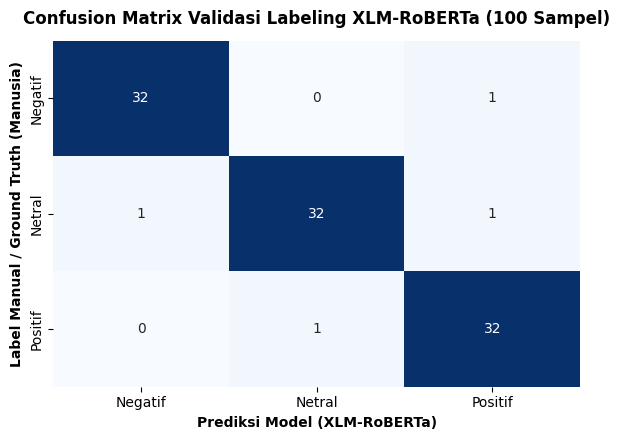

In [74]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = df_validasi['label_manual']
y_pred = df_validasi['sentimen']

# 1. Cetak Laporan Evaluasi Presisi, Recall, F1-Score & Akurasi
print("==========================================================")
print("       EVALUASI MATRIKS PELABELAN MODEL XLM-RoBERTa       ")
print("==========================================================")
print(classification_report(y_true, y_pred, target_names=['negatif', 'netral', 'positif']))

# 2. Plot Visualisasi Heatmap Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=['negatif', 'netral', 'positif'])

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Negatif', 'Netral', 'Positif'],
            yticklabels=['Negatif', 'Netral', 'Positif'])

plt.title('Confusion Matrix Validasi Labeling XLM-RoBERTa (100 Sampel)', fontweight='bold', pad=12)
plt.xlabel('Prediksi Model (XLM-RoBERTa)', fontweight='bold')
plt.ylabel('Label Manual / Ground Truth (Manusia)', fontweight='bold')
plt.tight_layout()
plt.show()

Tahap 5 : EDA (Exploratory Data Analysis)

In [83]:
df = df_validasi
df

,video_url,author,likes,comment_clean,is_oot,bahasa,sentimen,label_manual
0,https://www.youtube.com/watch?v=0LOHWGQwKtM,@williamfisher74,2,Hopefully people will rise up against it before it puts everyone out of work,True,Inggris,negatif,negatif
1,https://www.youtube.com/watch?v=F8pz5wIO6gA,@iskandarbazar3435,0,tidak setuju,True,Indonesia,negatif,negatif
2,https://www.youtube.com/watch?v=0LOHWGQwKtM,@Icemanmodeler,10,"Worked 10 years in games as a senior character artists, been making statues in my free time now ...",True,Inggris,negatif,negatif
3,https://www.youtube.com/watch?v=7Pq-S557XQU,@vulk_nubium,17,Our very concept of salary and work will be deprecated and we would have to rebuild our society ...,True,Inggris,negatif,negatif
4,https://www.youtube.com/watch?v=7Pq-S557XQU,@deplizz7859,2,No actually,True,Inggris,negatif,negatif
...,...,...,...,...,...,...,...,...
95,https://www.youtube.com/watch?v=t2WmNcToB3I,@indraasnarisamura3873,0,Hayoo gas AI sangat membantu saya,False,Tagalog,positif,positif
96,https://www.youtube.com/watch?v=0LOHWGQwKtM,@dirremoire,0,"Uh, AI does work and it's getting better every month. It's definitely working well enough so tha...",False,Inggris,positif,positif
97,https://www.youtube.com/watch?v=s1c4Ji6tNdw,@ipredictariot6371,0,exactly! I predict that we will see a large increase in the # of CEOs.,True,Inggris,positif,positif
98,https://www.youtube.com/watch?v=SDich6serU0,@Wandering_Weeb,2,Thank you,True,Inggris,positif,positif


In [84]:
df = df.drop(columns=['is_oot', 'label_manual'])

In [85]:
df

,video_url,author,likes,comment_clean,bahasa,sentimen
0,https://www.youtube.com/watch?v=0LOHWGQwKtM,@williamfisher74,2,Hopefully people will rise up against it before it puts everyone out of work,Inggris,negatif
1,https://www.youtube.com/watch?v=F8pz5wIO6gA,@iskandarbazar3435,0,tidak setuju,Indonesia,negatif
2,https://www.youtube.com/watch?v=0LOHWGQwKtM,@Icemanmodeler,10,"Worked 10 years in games as a senior character artists, been making statues in my free time now ...",Inggris,negatif
3,https://www.youtube.com/watch?v=7Pq-S557XQU,@vulk_nubium,17,Our very concept of salary and work will be deprecated and we would have to rebuild our society ...,Inggris,negatif
4,https://www.youtube.com/watch?v=7Pq-S557XQU,@deplizz7859,2,No actually,Inggris,negatif
...,...,...,...,...,...,...
95,https://www.youtube.com/watch?v=t2WmNcToB3I,@indraasnarisamura3873,0,Hayoo gas AI sangat membantu saya,Tagalog,positif
96,https://www.youtube.com/watch?v=0LOHWGQwKtM,@dirremoire,0,"Uh, AI does work and it's getting better every month. It's definitely working well enough so tha...",Inggris,positif
97,https://www.youtube.com/watch?v=s1c4Ji6tNdw,@ipredictariot6371,0,exactly! I predict that we will see a large increase in the # of CEOs.,Inggris,positif
98,https://www.youtube.com/watch?v=SDich6serU0,@Wandering_Weeb,2,Thank you,Inggris,positif


In [92]:
df['video_url'].unique()

array(['https://www.youtube.com/watch?v=0LOHWGQwKtM',
       'https://www.youtube.com/watch?v=F8pz5wIO6gA',
       'https://www.youtube.com/watch?v=7Pq-S557XQU',
       'https://www.youtube.com/watch?v=s1c4Ji6tNdw',
       'https://www.youtube.com/watch?v=t2WmNcToB3I',
       'https://www.youtube.com/watch?v=SDich6serU0'], dtype=object)

In [93]:
# 1. Pemetaan 6 URL Unik YouTube Persis dari Dataset
url_to_title = {
    'https://www.youtube.com/watch?v=0LOHWGQwKtM': 'Video 1: AI & PHK (Bahasa Indonesia)',
    'https://www.youtube.com/watch?v=F8pz5wIO6gA': 'Video 2: Impact of AI on Jobs (Inggris)',
    'https://www.youtube.com/watch?v=7Pq-S557XQU': 'Video 3: Future of Work AI (Inggris)',
    'https://www.youtube.com/watch?v=s1c4Ji6tNdw': 'Video 4: AI Replacing Jobs (Inggris)',
    'https://www.youtube.com/watch?v=t2WmNcToB3I': 'Video 5: AI & Automation (Inggris)',
    'https://www.youtube.com/watch?v=SDich6serU0': 'Video 6: Dampak AI Terhadap Industri (Indonesia)'
}

# 2. Buat kolom video_title
df['video_title'] = df['video_url'].map(url_to_title)

# 3. Buat juga label angka (video_code: 1, 2, 3, 4, 5, 6)
df['video_code'] = df['video_url'].map({url: i+1 for i, url in enumerate(url_to_title.keys())})

# 4. Sisipkan kolom 'video_title' dan 'video_code' tepat di sebelah kanan 'video_url'
kolom = list(df.columns)
kolom.remove('video_title')
kolom.remove('video_code')
idx = kolom.index('video_url')
kolom.insert(idx + 1, 'video_title')
kolom.insert(idx + 2, 'video_code')
df = df[kolom]

# 5. Cek Hasil (Dijamin tidak ada yang 'Video Lainnya' lagi!)
print("✅ Pemetaan 6 Video Berhasil!")
display(df[['video_url', 'video_title', 'video_code', 'comment_clean', 'sentimen']].head(10))

✅ Pemetaan 6 Video Berhasil!


,video_url,video_title,video_code,comment_clean,sentimen
0,https://www.youtube.com/watch?v=0LOHWGQwKtM,Video 1: AI & PHK (Bahasa Indonesia),1,Hopefully people will rise up against it before it puts everyone out of work,negatif
1,https://www.youtube.com/watch?v=F8pz5wIO6gA,Video 2: Impact of AI on Jobs (Inggris),2,tidak setuju,negatif
2,https://www.youtube.com/watch?v=0LOHWGQwKtM,Video 1: AI & PHK (Bahasa Indonesia),1,"Worked 10 years in games as a senior character artists, been making statues in my free time now ...",negatif
3,https://www.youtube.com/watch?v=7Pq-S557XQU,Video 3: Future of Work AI (Inggris),3,Our very concept of salary and work will be deprecated and we would have to rebuild our society ...,negatif
4,https://www.youtube.com/watch?v=7Pq-S557XQU,Video 3: Future of Work AI (Inggris),3,No actually,negatif
5,https://www.youtube.com/watch?v=s1c4Ji6tNdw,Video 4: AI Replacing Jobs (Inggris),4,The job market in sales is going to see wages collapse if data entry clerks migrate over en masse.,negatif
6,https://www.youtube.com/watch?v=s1c4Ji6tNdw,Video 4: AI Replacing Jobs (Inggris),4,"In the companies that i'm familiar with, there's a hiring freeze and workers who leave are gener...",negatif
7,https://www.youtube.com/watch?v=s1c4Ji6tNdw,Video 4: AI Replacing Jobs (Inggris),4,I always dislike how people quote the CEO's of AI companies whilst ignoring that these executive...,negatif
8,https://www.youtube.com/watch?v=7Pq-S557XQU,Video 3: Future of Work AI (Inggris),3,Trucks aren’t driving themselves. Autonomous driving has stalled hard,negatif
9,https://www.youtube.com/watch?v=0LOHWGQwKtM,Video 1: AI & PHK (Bahasa Indonesia),1,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to b...",negatif


In [98]:
df = df.drop(columns=['video_url','video_code'])

In [99]:
df

,video_title,author,likes,comment_clean,bahasa,sentimen
0,Video 1: AI & PHK (Bahasa Indonesia),@williamfisher74,2,Hopefully people will rise up against it before it puts everyone out of work,Inggris,negatif
1,Video 2: Impact of AI on Jobs (Inggris),@iskandarbazar3435,0,tidak setuju,Indonesia,negatif
2,Video 1: AI & PHK (Bahasa Indonesia),@Icemanmodeler,10,"Worked 10 years in games as a senior character artists, been making statues in my free time now ...",Inggris,negatif
3,Video 3: Future of Work AI (Inggris),@vulk_nubium,17,Our very concept of salary and work will be deprecated and we would have to rebuild our society ...,Inggris,negatif
4,Video 3: Future of Work AI (Inggris),@deplizz7859,2,No actually,Inggris,negatif
...,...,...,...,...,...,...
95,Video 5: AI & Automation (Inggris),@indraasnarisamura3873,0,Hayoo gas AI sangat membantu saya,Tagalog,positif
96,Video 1: AI & PHK (Bahasa Indonesia),@dirremoire,0,"Uh, AI does work and it's getting better every month. It's definitely working well enough so tha...",Inggris,positif
97,Video 4: AI Replacing Jobs (Inggris),@ipredictariot6371,0,exactly! I predict that we will see a large increase in the # of CEOs.,Inggris,positif
98,Video 6: Dampak AI Terhadap Industri (Indonesia),@Wandering_Weeb,2,Thank you,Inggris,positif


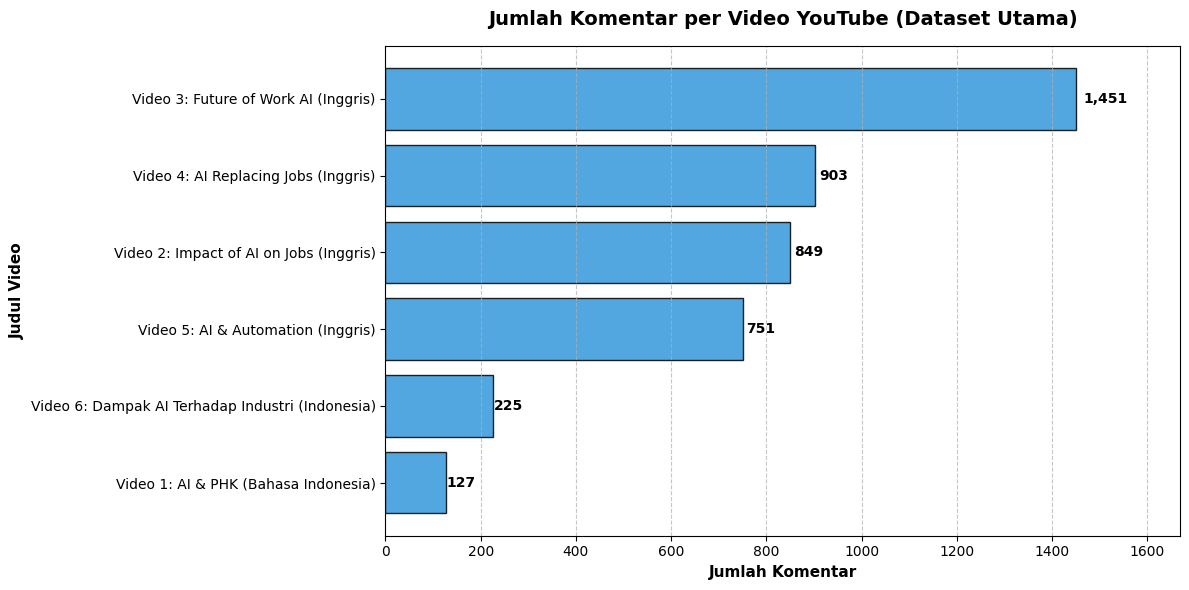

In [103]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca ulang file dataset utama yang berisi 4.300+ data
df_utama = pd.read_csv("youtube_comments_labeled.csv")

# 2. Map 6 URL Unik ke Judul Video
url_to_title = {
    'https://www.youtube.com/watch?v=0LOHWGQwKtM': 'Video 1: AI & PHK (Bahasa Indonesia)',
    'https://www.youtube.com/watch?v=F8pz5wIO6gA': 'Video 2: Impact of AI on Jobs (Inggris)',
    'https://www.youtube.com/watch?v=7Pq-S557XQU': 'Video 3: Future of Work AI (Inggris)',
    'https://www.youtube.com/watch?v=s1c4Ji6tNdw': 'Video 4: AI Replacing Jobs (Inggris)',
    'https://www.youtube.com/watch?v=t2WmNcToB3I': 'Video 5: AI & Automation (Inggris)',
    'https://www.youtube.com/watch?v=SDich6serU0': 'Video 6: Dampak AI Terhadap Industri (Indonesia)'
}

df_utama['video_title'] = df_utama['video_url'].map(url_to_title)

# 3. Hitung jumlah komentar asli per video
data_video = df_utama['video_title'].value_counts()

# 4. Buat Horizontal Bar Chart
plt.figure(figsize=(12, 6))
bars = plt.barh(data_video.index, data_video.values, color='#3498db', edgecolor='black', alpha=0.85)

# 5. Tambahkan Angka Total Komentar di Ujung Setiap Bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01),
             bar.get_y() + bar.get_height() / 2,
             f'{int(width):,}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 6. Label, Judul, dan Garis Bantu (Grid)
plt.title('Jumlah Komentar per Video YouTube (Dataset Utama)', fontweight='bold', fontsize=14, pad=15)
plt.xlabel('Jumlah Komentar', fontweight='bold', fontsize=11)
plt.ylabel('Judul Video', fontweight='bold', fontsize=11)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.xlim(0, max(data_video.values) * 1.15)

plt.tight_layout()
plt.show()

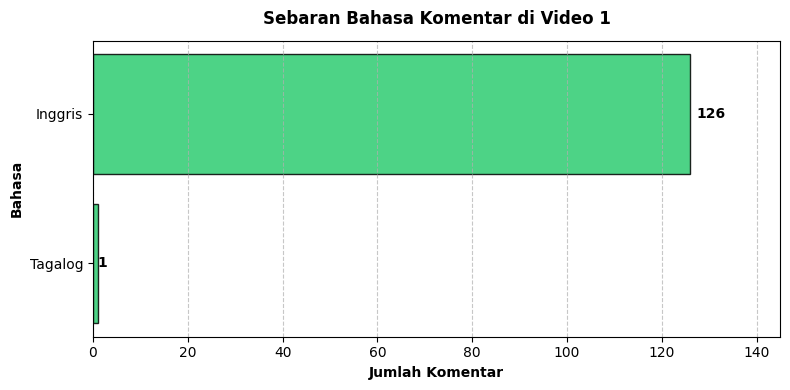

In [104]:
import matplotlib.pyplot as plt

# 1. Filter khusus data Video 1
df_v1 = df_utama[df_utama['video_title'] == 'Video 1: AI & PHK (Bahasa Indonesia)']

# 2. Hitung jumlah komentar per bahasa di Video 1
data_bahasa_v1 = df_v1['bahasa'].value_counts()

# 3. Buat Horizontal Bar Chart
plt.figure(figsize=(8, 4))
bars = plt.barh(data_bahasa_v1.index, data_bahasa_v1.values, color='#2ecc71', edgecolor='black', alpha=0.85)

# 4. Tambahkan Angka Jumlah Komentar di Ujung Setiap Bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01),
             bar.get_y() + bar.get_height() / 2,
             f'{int(width):,}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 5. Label, Judul, Grid, dan Setting Sumbu
plt.title('Sebaran Bahasa Komentar di Video 1', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Jumlah Komentar', fontweight='bold')
plt.ylabel('Bahasa', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.xlim(0, max(data_bahasa_v1.values) * 1.15)

plt.tight_layout()
plt.show()

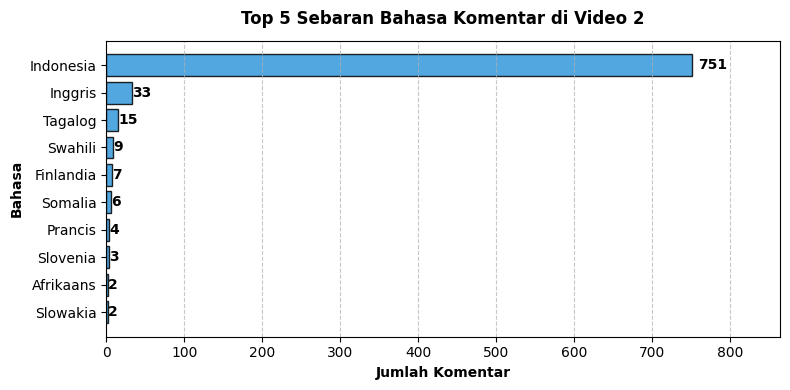

In [108]:
import matplotlib.pyplot as plt

# 1. Filter khusus data Video 2
df_v2 = df_utama[df_utama['video_title'] == 'Video 2: Impact of AI on Jobs (Inggris)']

# 2. Hitung Top 5 bahasa terbanyak di Video 2
data_bahasa_v2 = df_v2['bahasa'].value_counts().head(10)

# 3. Buat Horizontal Bar Chart
plt.figure(figsize=(8, 4))
bars = plt.barh(data_bahasa_v2.index, data_bahasa_v2.values, color='#3498db', edgecolor='black', alpha=0.85)

# 4. Tambahkan Angka Jumlah Komentar di Ujung Setiap Bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01),
             bar.get_y() + bar.get_height() / 2,
             f'{int(width):,}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 5. Label, Judul, Grid, dan Setting Sumbu
plt.title('Top 5 Sebaran Bahasa Komentar di Video 2', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Jumlah Komentar', fontweight='bold')
plt.ylabel('Bahasa', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.xlim(0, max(data_bahasa_v2.values) * 1.15)

plt.tight_layout()
plt.show()

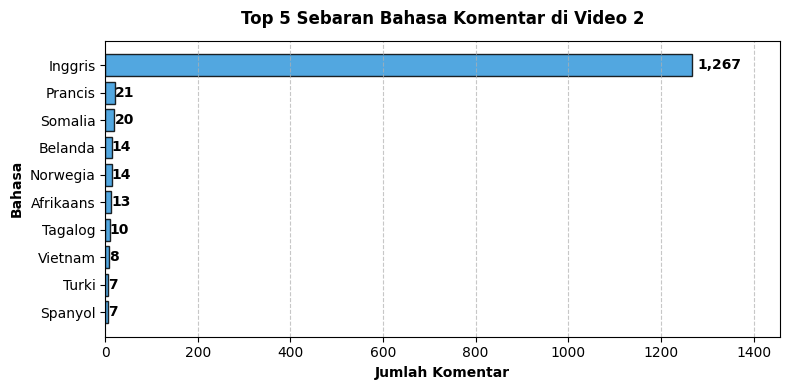

In [109]:
import matplotlib.pyplot as plt

# 1. Filter khusus data Video 2
df_v2 = df_utama[df_utama['video_title'] == 'Video 3: Future of Work AI (Inggris)']

# 2. Hitung Top 5 bahasa terbanyak di Video 2
data_bahasa_v2 = df_v2['bahasa'].value_counts().head(10)

# 3. Buat Horizontal Bar Chart
plt.figure(figsize=(8, 4))
bars = plt.barh(data_bahasa_v2.index, data_bahasa_v2.values, color='#3498db', edgecolor='black', alpha=0.85)

# 4. Tambahkan Angka Jumlah Komentar di Ujung Setiap Bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01),
             bar.get_y() + bar.get_height() / 2,
             f'{int(width):,}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 5. Label, Judul, Grid, dan Setting Sumbu
plt.title('Top 5 Sebaran Bahasa Komentar di Video 2', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Jumlah Komentar', fontweight='bold')
plt.ylabel('Bahasa', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.xlim(0, max(data_bahasa_v2.values) * 1.15)

plt.tight_layout()
plt.show()

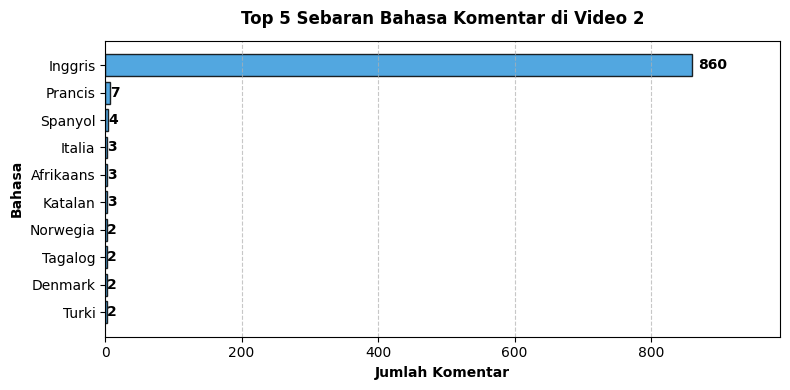

In [110]:
import matplotlib.pyplot as plt

# 1. Filter khusus data Video 2
df_v2 = df_utama[df_utama['video_title'] == 'Video 4: AI Replacing Jobs (Inggris)']

# 2. Hitung Top 5 bahasa terbanyak di Video 2
data_bahasa_v2 = df_v2['bahasa'].value_counts().head(10)

# 3. Buat Horizontal Bar Chart
plt.figure(figsize=(8, 4))
bars = plt.barh(data_bahasa_v2.index, data_bahasa_v2.values, color='#3498db', edgecolor='black', alpha=0.85)

# 4. Tambahkan Angka Jumlah Komentar di Ujung Setiap Bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01),
             bar.get_y() + bar.get_height() / 2,
             f'{int(width):,}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 5. Label, Judul, Grid, dan Setting Sumbu
plt.title('Top 5 Sebaran Bahasa Komentar di Video 2', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Jumlah Komentar', fontweight='bold')
plt.ylabel('Bahasa', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.xlim(0, max(data_bahasa_v2.values) * 1.15)

plt.tight_layout()
plt.show()

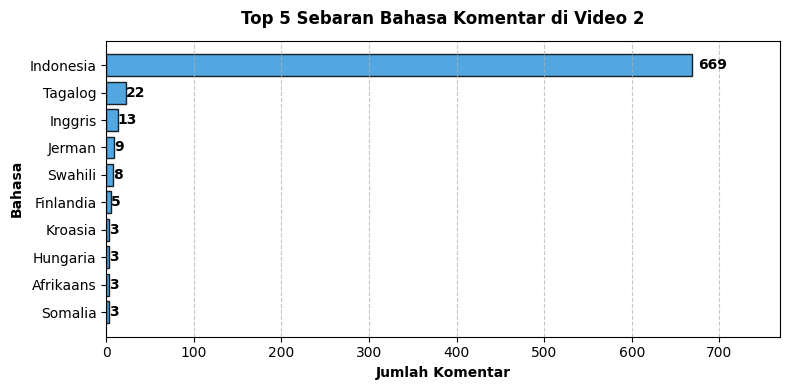

In [111]:
import matplotlib.pyplot as plt

# 1. Filter khusus data Video 2
df_v2 = df_utama[df_utama['video_title'] == 'Video 5: AI & Automation (Inggris)']

# 2. Hitung Top 5 bahasa terbanyak di Video 2
data_bahasa_v2 = df_v2['bahasa'].value_counts().head(10)

# 3. Buat Horizontal Bar Chart
plt.figure(figsize=(8, 4))
bars = plt.barh(data_bahasa_v2.index, data_bahasa_v2.values, color='#3498db', edgecolor='black', alpha=0.85)

# 4. Tambahkan Angka Jumlah Komentar di Ujung Setiap Bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01),
             bar.get_y() + bar.get_height() / 2,
             f'{int(width):,}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 5. Label, Judul, Grid, dan Setting Sumbu
plt.title('Top 5 Sebaran Bahasa Komentar di Video 2', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Jumlah Komentar', fontweight='bold')
plt.ylabel('Bahasa', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.xlim(0, max(data_bahasa_v2.values) * 1.15)

plt.tight_layout()
plt.show()

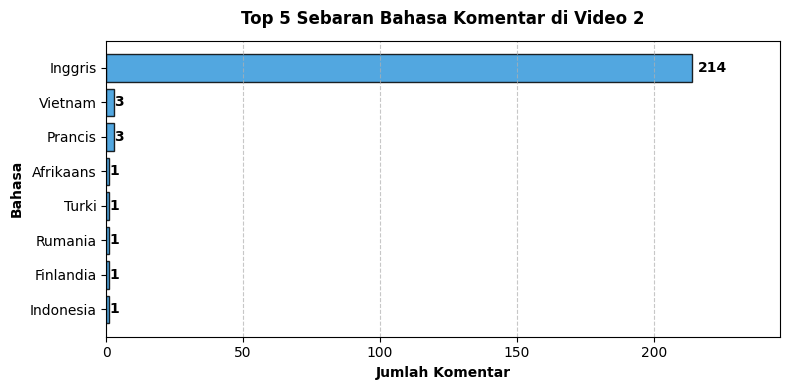

In [112]:
import matplotlib.pyplot as plt

# 1. Filter khusus data Video 2
df_v2 = df_utama[df_utama['video_title'] == 'Video 6: Dampak AI Terhadap Industri (Indonesia)']

# 2. Hitung Top 5 bahasa terbanyak di Video 2
data_bahasa_v2 = df_v2['bahasa'].value_counts().head(10)

# 3. Buat Horizontal Bar Chart
plt.figure(figsize=(8, 4))
bars = plt.barh(data_bahasa_v2.index, data_bahasa_v2.values, color='#3498db', edgecolor='black', alpha=0.85)

# 4. Tambahkan Angka Jumlah Komentar di Ujung Setiap Bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01),
             bar.get_y() + bar.get_height() / 2,
             f'{int(width):,}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 5. Label, Judul, Grid, dan Setting Sumbu
plt.title('Top 5 Sebaran Bahasa Komentar di Video 2', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Jumlah Komentar', fontweight='bold')
plt.ylabel('Bahasa', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.xlim(0, max(data_bahasa_v2.values) * 1.15)

plt.tight_layout()
plt.show()

In [113]:
df

,video_title,author,likes,comment_clean,bahasa,sentimen
0,Video 1: AI & PHK (Bahasa Indonesia),@williamfisher74,2,Hopefully people will rise up against it before it puts everyone out of work,Inggris,negatif
1,Video 2: Impact of AI on Jobs (Inggris),@iskandarbazar3435,0,tidak setuju,Indonesia,negatif
2,Video 1: AI & PHK (Bahasa Indonesia),@Icemanmodeler,10,"Worked 10 years in games as a senior character artists, been making statues in my free time now ...",Inggris,negatif
3,Video 3: Future of Work AI (Inggris),@vulk_nubium,17,Our very concept of salary and work will be deprecated and we would have to rebuild our society ...,Inggris,negatif
4,Video 3: Future of Work AI (Inggris),@deplizz7859,2,No actually,Inggris,negatif
...,...,...,...,...,...,...
95,Video 5: AI & Automation (Inggris),@indraasnarisamura3873,0,Hayoo gas AI sangat membantu saya,Tagalog,positif
96,Video 1: AI & PHK (Bahasa Indonesia),@dirremoire,0,"Uh, AI does work and it's getting better every month. It's definitely working well enough so tha...",Inggris,positif
97,Video 4: AI Replacing Jobs (Inggris),@ipredictariot6371,0,exactly! I predict that we will see a large increase in the # of CEOs.,Inggris,positif
98,Video 6: Dampak AI Terhadap Industri (Indonesia),@Wandering_Weeb,2,Thank you,Inggris,positif
